# 1. Business Understanding

## 1.1 Contexto do Problema

Instituições privadas de ensino superior precisam planejar, com antecedência, a quantidade de vagas que serão ofertadas em seus cursos.

No ensino presencial, essa decisão influencia diretamente o planejamento acadêmico, operacional e financeiro da instituição, pois a quantidade esperada de alunos pode afetar:

- formação e dimensionamento de turmas;
- alocação de docentes;
- utilização de salas e laboratórios;
- uso da infraestrutura física;
- planejamento de captação;
- projeções de receita.

Quando a quantidade de vagas ofertadas é significativamente superior à quantidade de alunos que efetivamente ingressam, a instituição pode apresentar **baixa ocupação das vagas e capacidade instalada subutilizada**.

Esse cenário pode resultar em turmas menores do que o planejado, menor aproveitamento da infraestrutura e aumento do custo operacional por aluno.

Dessa forma, estimar antecipadamente a demanda de ingressantes pode fornecer uma informação relevante para apoiar o planejamento da oferta de vagas.

## 1.2 Justificativa do Recorte

O projeto será direcionado às **Instituições de Ensino Superior privadas do Estado de São Paulo, na modalidade Presencial**.

A escolha da rede privada está relacionada à necessidade de planejamento da oferta de vagas e ao impacto que uma baixa ocupação pode gerar sobre a utilização dos recursos acadêmicos e operacionais.

O foco no ensino presencial ocorre porque essa modalidade depende de uma estrutura física e operacional diretamente relacionada ao volume de alunos, incluindo salas, laboratórios, docentes e demais recursos utilizados na formação das turmas.

O Estado de São Paulo será utilizado como recorte geográfico para manter o problema delimitado e permitir uma análise consistente da evolução histórica da demanda.

## 1.3 Problema de Negócio

Instituições privadas de ensino superior precisam definir sua oferta de vagas antes de conhecerem completamente a quantidade de alunos que efetivamente ingressará em seus cursos.

Quando a oferta é superior à demanda realizada, podem surgir vagas não preenchidas e capacidade operacional ociosa.

O problema de negócio deste projeto consiste em:

**Como utilizar o comportamento histórico dos cursos para estimar a quantidade futura de ingressantes e apoiar o planejamento da oferta de vagas em cursos presenciais de IES privadas do Estado de São Paulo?**

## 1.4 Objetivo de Negócio

Apoiar o planejamento da oferta de vagas de cursos presenciais de instituições privadas de ensino superior do Estado de São Paulo por meio da **estimativa antecipada da demanda de ingressantes**.

A previsão poderá ser utilizada como informação de apoio para identificar situações em que a quantidade de vagas planejadas esteja significativamente acima da demanda esperada, contribuindo para um dimensionamento mais eficiente da oferta.

## 1.5 Objetivo Analítico

Desenvolver e avaliar, **em entregas posteriores**, um modelo de regressão supervisionada com componente temporal capaz de prever o número de ingressantes em vagas novas dos cursos presenciais de IES privadas do Estado de São Paulo.

- **Variável observada:** `QTD_INGRESSANTES_VAGAS_NOVAS`.
- **Alvo futuro:** `QTD_INGRESSANTES_VAGAS_NOVAS(t+1)`.
- **Horizonte:** um ano à frente, a partir das informações disponíveis até o ano `t`.

**Características e histórico até `t` → modelo (etapa 4) → ingressantes previstos em `t+1`.**

A primeira entrega documenta as etapas 1 e 2; a etapa 3 abaixo prepara a base, sem realizar o treinamento.


## 1.6 Escopo do Projeto

O estudo considera:

- **Estado:** São Paulo;
- **Rede:** Privada;
- **Nível acadêmico:** Graduação;
- **Modalidade:** Presencial;
- **Período disponível:** 2015–2024;
- **Fonte:** Microdados do Censo da Educação Superior – INEP;
- **Unidade principal de análise:** curso ofertado por instituição e localidade;
- **Variável alvo:** `QTD_INGRESSANTES_VAGAS_NOVAS` no período seguinte.

O período disponível será utilizado para construção do histórico e desenvolvimento da estratégia de treinamento, validação e teste, sempre respeitando a ordem temporal dos dados.

## 1.7 Perguntas de Negócio

O projeto será orientado por uma pergunta principal e três perguntas de apoio.

### Pergunta principal

**É possível prever a quantidade de ingressantes em vagas novas de cursos presenciais de IES privadas do Estado de São Paulo para o próximo período utilizando seu comportamento histórico?**

### 1. Como a demanda por ingressantes em vagas novas evoluiu historicamente no período analisado?

### 2. Quais características históricas apresentam maior relação com a quantidade futura de ingressantes?

### 3. A previsão gerada pelo modelo pode apoiar a identificação de situações em que a oferta de vagas esteja significativamente acima da demanda esperada?

## 1.8 Hipóteses Iniciais

- **H1:** o histórico de ingressantes contém informação relevante para estimar a demanda no próximo ano.
- **H2:** históricos de vagas, inscrições e ingressantes, instituição, curso, **área CINE** e localização poderão contribuir para a previsão.
- **H3:** o cruzamento entre oferta planejada e demanda estimada poderá sinalizar capacidade potencialmente ociosa.
- **H4 (contextual):** a evolução da participação do EAD pode contribuir para interpretar transformações da demanda presencial.

Estas são hipóteses a investigar, **não conclusões causais ou de modelagem**.


## 1.9 Impacto Esperado

O projeto busca transformar dados históricos do Censo da Educação Superior em uma estimativa de demanda futura que possa apoiar o processo de planejamento de vagas.

A principal aplicação de negócio será a comparação entre a demanda prevista e a oferta planejada.

Uma medida de apoio poderá ser definida como:

**Gap de capacidade = Vagas planejadas − Demanda prevista**

Valores elevados desse indicador podem sinalizar situações em que a oferta esteja significativamente superior à demanda estimada.

Esse indicador não deverá ser interpretado como uma recomendação automática de redução de vagas, mas como um **sinal de apoio à tomada de decisão**, que poderá ser combinado com informações acadêmicas, comerciais e estratégicas da instituição.

## 1.10 Critérios de Sucesso (planejados)

**Analíticos:** comparar o modelo com um baseline temporal e avaliar **MAE, RMSE, WAPE e R²**, preservando 2024 como *holdout* final. Interpretar o MAE em número de ingressantes e verificar estabilidade por área CINE, curso, município e IES.

**De negócio:** gerar previsão por curso/IES/localidade e apoiar o cálculo futuro:

`Gap de capacidade = vagas planejadas − demanda prevista`

Valores positivos elevados representam um **alerta para investigação**, não uma recomendação automática de encerramento ou redução de vagas. Não utilizar MAPE como indicador principal em uma base com muitos valores zero no denominador.


## 1.11 Estratégia de Modelagem Planejada

Como o objetivo do projeto é estimar uma **quantidade futura de ingressantes**, o problema será tratado como uma tarefa de **regressão supervisionada com componente temporal**.

Para cada combinação de instituição, curso e localidade, informações disponíveis até o período `t` serão utilizadas para prever:

**`QTD_INGRESSANTES_VAGAS_NOVAS(t+1)`**

A modelagem será conduzida de forma comparativa. Em vez de assumir previamente um único algoritmo como solução definitiva, serão avaliados modelos com diferentes níveis de complexidade, partindo de um baseline simples até algoritmos capazes de capturar relações não lineares e interações entre variáveis.

### Modelos principais

| Modelo | Papel no projeto | Motivo da escolha |
|---|---|---|
| **Baseline temporal (Lag-1 / último valor observado)** | Referência mínima de desempenho | Permite verificar se os modelos de Machine Learning realmente produzem ganho em relação à regra simples de utilizar a demanda do ano anterior como previsão do próximo período. |
| **Ridge Regression** | Modelo linear de referência | É simples, interpretável e utiliza regularização para reduzir instabilidade causada por variáveis correlacionadas e pela expansão de variáveis categóricas. Permite avaliar se a relação entre histórico e demanda futura pode ser explicada adequadamente por uma estrutura aproximadamente linear. |
| **Poisson Regressor** | Modelo de regressão para contagens | A variável alvo representa uma quantidade de ingressantes e, portanto, assume valores não negativos. O modelo de Poisson é adequado para esse tipo de variável e permite comparar uma abordagem estatística específica para dados de contagem com os demais modelos. |
| **Random Forest Regressor** | Modelo não linear baseado em árvores | Consegue capturar interações e relações não lineares entre características como histórico de ingressantes, inscrições, instituição, curso e localidade, além de ser relativamente robusto a outliers. |
| **XGBoost Regressor** | Modelo de boosting para dados tabulares | É adequado para dados tabulares e permite modelar relações complexas entre variáveis, combinando regularização e árvores sequenciais. Será utilizado para verificar se um modelo mais flexível melhora a capacidade preditiva. |
| **CatBoost Regressor** | Modelo de boosting com foco em variáveis categóricas | É particularmente interessante para este projeto devido à presença de variáveis como IES, curso, município, área CINE e grau acadêmico. O CatBoost lida de forma eficiente com variáveis categóricas e pode reduzir a necessidade de uma expansão muito grande por One-Hot Encoding. |

### Modelos complementares

Os modelos abaixo poderão ser avaliados como testes adicionais, caso seja necessário ampliar a comparação:

| Modelo | Possível contribuição |
|---|---|
| **Elastic Net** | Combina as penalizações L1 e L2 e pode ser útil quando houver muitas variáveis após a codificação das categorias, ajudando no controle de multicolinearidade e seleção de características. |
| **Extra Trees Regressor** | É semelhante ao Random Forest, mas adiciona maior aleatoriedade na criação das árvores. Pode funcionar como comparação adicional entre métodos de ensemble baseados em árvores. |
| **HistGradientBoosting Regressor** | Implementa boosting de forma eficiente para dados tabulares e permite trabalhar com diferentes funções de perda, incluindo Poisson, o que pode ser útil para a natureza de contagem do target. |
| **LightGBM Regressor** | É eficiente para bases tabulares com grande volume de registros e muitas variáveis. Poderá ser testado caso o volume de dados torne necessário um algoritmo de boosting mais rápido e eficiente. |

### Critério para escolha dos modelos

A inclusão de vários algoritmos não tem como objetivo escolher o modelo mais complexo, mas comparar diferentes famílias de métodos:

**Baseline → Linear → Contagem → Bagging → Boosting**

Essa estrutura permitirá avaliar se o aumento da complexidade realmente gera ganho de desempenho preditivo.

A seleção do modelo final não será realizada apenas pelo maior `R²`. Serão consideradas principalmente métricas de erro que possam ser interpretadas no contexto do negócio, como:

- **MAE**;
- **RMSE**;
- **WAPE**;
- **R²**.

O **MAE** terá papel importante porque permite interpretar o erro diretamente em número de alunos. Por exemplo, um `MAE = 18` indicaria que, em média, a previsão apresenta um erro absoluto de aproximadamente 18 ingressantes por observação.

Além do desempenho médio, também será considerada a estabilidade do modelo nos períodos mais recentes e sua capacidade de generalização para dados ainda não observados.

### Observação sobre modelos clássicos de séries temporais

Modelos como **ARIMA**, **SARIMA** e **Prophet** não serão priorizados como modelos principais neste projeto.

Apesar de o problema possuir componente temporal, a base é formada por várias combinações de:

**IES × Curso × Município × Ano**

e cada combinação possui uma série histórica relativamente curta.

Por esse motivo, a estratégia principal será transformar o histórico em atributos temporais, como `lag`, médias móveis e taxas de crescimento, e utilizar essas informações em modelos supervisionados de regressão.

Essa abordagem permite aproveitar simultaneamente o histórico temporal e as características estruturais de cada curso, instituição e localidade.

### 1.11.2 Variáveis Explicativas Planejadas

#### Variáveis temporais

| Variável | Forma de utilização | Justificativa |
|---|---|---|
| `ANO_CENSO` | Variável temporal | Permite representar mudanças estruturais ao longo do tempo e auxiliar o modelo a capturar tendências gerais do mercado. |

#### Características da instituição, curso e mercado local

| Variável | Forma de utilização | Justificativa |
|---|---|---|
| `COD_IES` | Categórica | Instituições possuem porte, posicionamento, reconhecimento e comportamento histórico diferentes, que podem afetar a quantidade de ingressantes. |
| `COD_CURSO` | Categórica | A demanda varia significativamente entre cursos. A identificação do curso permite preservar esse comportamento específico ao longo do tempo. |
| `COD_MUNICIPIO` / `NOME_MUNICIPIO_CURSO` | Categórica | A procura por ensino superior pode variar conforme o mercado local, concentração populacional, concorrência e características regionais. |
| `NOME_AREA_GERAL_CINE` | Categórica | Cursos de uma mesma área de formação podem apresentar padrões de demanda semelhantes, além de tendências de crescimento ou retração específicas. |
| `GRAU_ACADEMICO` | Categórica | Bacharelados, licenciaturas e cursos tecnológicos podem possuir perfis de procura e duração diferentes. |

As variáveis `COD_REDE`, `SIGLA_UF_CURSO` e `MODALIDADE_ENSINO` não deverão contribuir diretamente para o modelo após a aplicação do recorte, pois todas as observações analisadas pertencerão à **rede privada**, ao **Estado de São Paulo** e à modalidade **Presencial**. Portanto, essas variáveis terão pouca ou nenhuma variação dentro do conjunto utilizado para modelagem.

### 1.11.3 Variáveis Históricas de Demanda

As principais informações quantitativas serão utilizadas prioritariamente em sua forma histórica.

| Feature planejada | Origem | Justificativa |
|---|---|---|
| `INGRESSANTES_LAG_1` | `QTD_INGRESSANTES_VAGAS_NOVAS` do ano anterior | Representa o nível mais recente de demanda efetivamente realizada e deverá funcionar como uma das principais referências para prever o período seguinte. |
| `INGRESSANTES_LAG_2` | Ingressantes de dois anos anteriores | Permite observar se o comportamento recente é persistente ou se houve mudança em relação a períodos anteriores. |
| `MEDIA_INGRESSANTES_3_ANOS` | Média histórica de ingressantes | Reduz o efeito de oscilações pontuais e representa o nível recente de demanda do curso. |
| `CRESCIMENTO_INGRESSANTES` | Variação entre períodos | Permite representar tendência de crescimento ou retração da demanda. |
| `VAGAS_LAG_1` | `QTD_VAGAS_NOVAS` do período anterior | Representa o histórico recente da capacidade/oferta disponibilizada pela instituição. |
| `INSCRICOES_LAG_1` | `QTD_INSCRICOES_VAGAS_NOVAS` do período anterior | As inscrições representam manifestação de interesse anterior ao ingresso e podem fornecer sinal relevante sobre o nível de procura pelo curso. |
| `RELACAO_INSCRICOES_VAGAS_LAG_1` | Inscrições ÷ vagas do período anterior | Representa a pressão histórica de procura em relação à oferta disponível. |
| `TAXA_OCUPACAO_LAG_1` | Ingressantes ÷ vagas do período anterior | Indica historicamente quanto da oferta de vagas foi convertida em ingresso efetivo. |

### 1.11.4 Variáveis de Acesso e Financiamento

As variáveis:

- `QTD_FIES`;
- `QTD_PROUNI`;
- `QTD_FINANCIAMENTO`;

podem apresentar relação com a capacidade de ingresso dos estudantes e, portanto, serão avaliadas durante a análise exploratória.

Entretanto, elas somente serão utilizadas caso estejam disponíveis no momento da previsão. Caso representem informações consolidadas apenas após o ingresso, serão utilizadas exclusivamente em sua versão histórica, por exemplo:

- `FIES_LAG_1`;
- `PROUNI_LAG_1`;
- `FINANCIAMENTO_LAG_1`.

A inclusão definitiva dessas variáveis dependerá de evidências encontradas na análise exploratória e da ausência de vazamento de informação.

### 1.11.5 Variáveis que exigem cuidado ou não serão utilizadas diretamente

Algumas variáveis possuem relação muito próxima com o resultado que se deseja prever e, se utilizadas no período incorreto, podem gerar uma falsa impressão de desempenho.

Por exemplo:

- `QTD_INGRESSANTES_TOTAL`;
- `QTD_INGRESSANTES_FEMININO`;
- `QTD_INGRESSANTES_MASCULINO`;
- `QTD_CONCLUINTES`;
- `QTD_INSCRICOES_VAGAS_NOVAS`;
- `QTD_FIES`;
- `QTD_PROUNI`;
- `QTD_FINANCIAMENTO`.

Para prever o ano `t+1`, essas informações não deverão ser utilizadas com valores referentes ao próprio período `t+1` caso ainda não estivessem disponíveis no momento real da previsão.

Também será evitada a utilização simultânea de variáveis textuais e seus respectivos códigos quando representarem exatamente a mesma informação, como `COD_IES` e `NOME_IES`, para reduzir redundância.

A regra principal será:

**o modelo só poderá utilizar informações que estariam disponíveis antes do período que está sendo previsto.**

### 1.11.6 Exemplo da Estrutura Preditiva

Considerando uma determinada combinação de IES, curso e município:

| Informações disponíveis até 2023 | Variável a prever |
|---|---|
| Ingressantes em 2023 | |
| Ingressantes em 2022 | |
| Média de ingressantes dos últimos anos | |
| Vagas ofertadas em 2023 | **Ingressantes em 2024** |
| Inscrições registradas em 2023 | |
| Área CINE | |
| Município | |
| Instituição e curso | |

De forma conceitual:

**Características estruturais + histórico da demanda até `t` → Modelo → `QTD_INGRESSANTES_VAGAS_NOVAS(t+1)`**

Após a geração da previsão, o resultado poderá ser comparado à oferta planejada de vagas:

**Gap de capacidade = Vagas planejadas − Demanda prevista**

Essa comparação permitirá transformar a saída do modelo em uma informação diretamente relacionada ao problema de negócio.

## 1.12 Carga Extensionista

# 2. Data Understanding — Compreensão dos Dados


### Importando Dados e Bibliotecas 

In [1]:
# Bibliotecas usadas nas etapas 1–3
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import snowflake.connector
from dotenv import find_dotenv, load_dotenv
from IPython.display import display

plt.style.use('ggplot')
pd.set_option('display.max_columns', 40)


In [2]:
# Fonte de dados
env_path = find_dotenv(usecwd=True)
load_dotenv(env_path, override=True)

def get_env(*names, required=True):
    for name in names:
        value = os.getenv(name)
        if value:
            return value
    if required:
        raise ValueError("Variavel de ambiente ausente: " + " ou ".join(names))
    return None

conn = snowflake.connector.connect(
    account=get_env("SF_ACCOUNT", "SNOWFLAKE_ACCOUNT"),
    user=get_env("SF_USER", "SNOWFLAKE_USER"),
    password=get_env("SF_PASSWORD", "SNOWFLAKE_PASSWORD"),
    warehouse=get_env("SF_WAREHOUSE", "SNOWFLAKE_WAREHOUSE"),
    database=get_env("SF_DATABASE", "SNOWFLAKE_DATABASE"),
    schema=get_env("SF_SCHEMA", "SNOWFLAKE_SCHEMA"),
    role=get_env("SF_ROLE", "SNOWFLAKE_ROLE", required=False)
)

print("Conectado ao Snowflake")

Conectado ao Snowflake


In [3]:
# Consulta à VIEW analítica; nenhuma inserção ou alteração é feita no Snowflake.
# A VIEW tem recorte de SP + rede privada; a modalidade será verificada separadamente.
query = """
SELECT *
FROM PROJETO_INEP.ANALYTICS.VW_CURSOS_SP_PRIVADA_2015_2024_ML
ORDER BY ANO_CENSO, COD_IES, COD_CURSO
"""
with conn.cursor() as cursor:
    cursor.execute(query)
    df = cursor.fetch_pandas_all()

print(f"Fonte carregada: {len(df):,} registros e {df.shape[1]} colunas")


Fonte carregada: 698,004 registros e 27 colunas


## 2.1 Fonte dos Dados

A fonte principal são os **Microdados do Censo da Educação Superior (INEP), anos de 2015 a 2024**. O projeto utiliza o Snowflake nas camadas **STAGE** (brutos), **TRUSTED** (harmonização) e **ANALYTICS** (visões de consumo). Neste notebook a extração ocorre na VIEW `PROJETO_INEP.ANALYTICS.VW_CURSOS_SP_PRIVADA_2015_2024_ML`.

**Distinção importante:** embora a VIEW seja identificada como São Paulo/rede privada, a base exploratória contém **Presencial e EAD**, para comparação contextual. O filtro **Presencial** será aplicado explicitamente somente à base de modelagem, na etapa 3. Os códigos de rede e a restrição a graduação precisam ser conferidos com as regras SQL da VIEW; não se deve adivinhar o significado de `COD_REDE`.

Números apresentados no relatório parcial (698.004 observações, 27 variáveis) referem-se à **base original**, antes do filtro e do tratamento. Os diagnósticos abaixo recalculam os valores ao executar o notebook.


### Informações dos dados

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 698004 entries, 0 to 698003
Data columns (total 27 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   ANO_CENSO                     698004 non-null  int16  
 1   COD_IES                       698004 non-null  int16  
 2   NOME_IES                      698004 non-null  object 
 3   SIGLA_IES                     625076 non-null  object 
 4   ORGANIZACAO_ACADEMICA         698004 non-null  int8   
 5   COD_REDE                      698004 non-null  int8   
 6   COD_CURSO                     698004 non-null  int32  
 7   NOME_CURSO                    698004 non-null  object 
 8   COD_MUNICIPIO                 698004 non-null  int32  
 9   NOME_MUNICIPIO_CURSO          698004 non-null  object 
 10  SIGLA_UF_CURSO                698004 non-null  object 
 11  COD_CINE                      698004 non-null  object 
 12  NOME_AREA_GERAL_CINE          698004 non-nul

## 2.2 Granularidade dos Dados

A unidade de observação representa a combinação de características relacionadas a:

- ano do Censo;
- instituição de ensino superior;
- curso;
- município de oferta;
- modalidade de ensino;
- grau acadêmico;
- área de formação CINE.

Assim, um mesmo curso pode aparecer em diferentes anos, instituições, municípios ou modalidades.

A granularidade deverá ser validada antes da modelagem para garantir que não existam duplicidades indevidas para a chave analítica considerada.

## 2.3 Estrutura das Variáveis

### Variáveis temporais

| Variável | Descrição | Tipo |
|---|---|---|
| `ANO_CENSO` | Ano de referência do Censo da Educação Superior | Numérica |

### Instituição de Ensino Superior

| Variável | Descrição | Tipo |
|---|---|---|
| `COD_IES` | Código identificador da instituição | Numérica |
| `NOME_IES` | Nome da instituição de ensino superior | Categórica |
| `SIGLA_IES` | Sigla da instituição | Categórica |
| `ORGANIZACAO_ACADEMICA` | Tipo de organização acadêmica | Categórica codificada |
| `COD_REDE` | Código da rede de ensino | Categórica codificada |

### Curso e localização

| Variável | Descrição | Tipo |
|---|---|---|
| `COD_CURSO` | Código identificador do curso | Numérica/identificadora |
| `NOME_CURSO` | Nome do curso | Categórica |
| `COD_MUNICIPIO` | Código do município de oferta | Categórica codificada |
| `NOME_MUNICIPIO_CURSO` | Município onde o curso é ofertado | Categórica |
| `SIGLA_UF_CURSO` | Unidade da Federação da oferta | Categórica |

### Área e características acadêmicas

| Variável | Descrição | Tipo |
|---|---|---|
| `COD_CINE` | Código da área geral de formação CINE | Categórica |
| `NOME_AREA_GERAL_CINE` | Área geral de formação CINE | Categórica |
| `MODALIDADE_ENSINO` | Modalidade de ensino, como Presencial ou EAD | Categórica |
| `GRAU_ACADEMICO` | Código do grau acadêmico | Categórica codificada |

### Oferta e demanda

| Variável | Descrição | Tipo |
|---|---|---|
| `QTD_CURSOS` | Quantidade de cursos | Numérica |
| `QTD_VAGAS_TOTAL` | Total de vagas ofertadas | Numérica |
| `QTD_VAGAS_NOVAS` | Quantidade de vagas novas ofertadas | Numérica |
| `QTD_INSCRICOES_VAGAS_NOVAS` | Número de inscrições para vagas novas | Numérica |
| `QTD_INGRESSANTES_TOTAL` | Total de ingressantes | Numérica |
| `QTD_INGRESSANTES_VAGAS_NOVAS` | Quantidade de ingressantes por vagas novas | Numérica |
| `QTD_INGRESSANTES_FEMININO` | Quantidade de ingressantes do sexo feminino | Numérica |
| `QTD_INGRESSANTES_MASCULINO` | Quantidade de ingressantes do sexo masculino | Numérica |
| `QTD_CONCLUINTES` | Quantidade de concluintes | Numérica |

### Financiamento estudantil

| Variável | Descrição | Tipo |
|---|---|---|
| `QTD_FIES` | Quantidade de ingressantes vinculados ao FIES | Numérica |
| `QTD_PROUNI` | Quantidade de ingressantes vinculados ao PROUNI | Numérica |
| `QTD_FINANCIAMENTO` | Quantidade de ingressantes com algum tipo de financiamento | Numérica |

## 2.4 Variável Alvo

O objetivo principal do projeto é estimar a demanda futura por vagas no ensino superior privado.

A variável inicialmente definida como **target** é:

`QTD_INGRESSANTES_VAGAS_NOVAS`

Essa variável representa a quantidade de estudantes que efetivamente ingressaram por meio das vagas novas ofertadas.

O problema será tratado como uma tarefa de **regressão supervisionada**, pois a variável alvo é quantitativa.

## 2.5 Variáveis Explicativas Iniciais

Entre as variáveis com potencial de utilização como preditoras estão:

- `QTD_VAGAS_NOVAS`;
- `QTD_INSCRICOES_VAGAS_NOVAS`;
- `QTD_CURSOS`;
- `COD_IES`;
- `COD_MUNICIPIO`;
- `NOME_AREA_GERAL_CINE`;
- `MODALIDADE_ENSINO`;
- `GRAU_ACADEMICO`;
- `QTD_FIES`;
- `QTD_PROUNI`;
- `QTD_FINANCIAMENTO`;
- histórico de ingressantes;
- histórico de vagas;
- histórico de inscrições.

A seleção definitiva será realizada após a análise exploratória e a avaliação do risco de vazamento de informação.

## 2.6 Atenção ao Data Leakage

Como o objetivo é realizar uma previsão temporal, uma variável somente poderá ser utilizada como preditora se estiver disponível no momento em que a previsão for realizada.

Por exemplo, para prever os ingressantes de 2024 utilizando informações disponíveis até 2023, não devem ser utilizadas como entrada informações observadas somente após o processo de ingresso de 2024.

Dessa forma, variáveis como:

- `QTD_INSCRICOES_VAGAS_NOVAS`;
- `QTD_INGRESSANTES_TOTAL`;
- `QTD_CONCLUINTES`;

precisam ser avaliadas quanto ao momento em que ficam disponíveis.

Uma possível estratégia será utilizar versões históricas dessas variáveis, como:

- ingressantes do ano anterior;
- vagas do ano anterior;
- inscrições do ano anterior;
- média móvel dos últimos anos;
- crescimento percentual anual.

## 2.7 Qualidade e Higiene dos Dados

Nesta etapa são **diagnosticados**, sem exclusões automáticas: nulos, duplicidades, valores negativos, coberturas anuais, domínios de categoria e códigos sem descrição. As decisões de transformação são implementadas na etapa 3.

A chave preliminar a verificar é `ANO_CENSO + COD_IES + COD_CURSO + COD_MUNICIPIO + MODALIDADE_ENSINO`; a granularidade real deve ser confirmada antes de combinar registros ou criar séries anuais. A comparação Presencial × EAD continua apenas como **contexto de mercado**, não compõe o conjunto final de treinamento.


### Dados Ausentes

In [5]:
# Diagnóstico de ausentes ANTES de qualquer tratamento
resumo_nulos = (
    pd.DataFrame({
        'NULOS': df.isna().sum(),
        'PERCENTUAL_NULOS': (df.isna().mean() * 100).round(3),
        'TIPO': df.dtypes.astype(str)
    })
    .sort_values('NULOS', ascending=False)
)
display(resumo_nulos)


,NULOS,PERCENTUAL_NULOS,TIPO
SIGLA_IES,72928,10.448,object
GRAU_ACADEMICO,819,0.117,float64
COD_IES,0,0.000,int16
NOME_IES,0,0.000,object
ORGANIZACAO_ACADEMICA,0,0.000,int8
COD_REDE,0,0.000,int8
COD_CURSO,0,0.000,int32
NOME_CURSO,0,0.000,object
COD_MUNICIPIO,0,0.000,int32
NOME_MUNICIPIO_CURSO,0,0.000,object


### 2.7.1 Duplicidades e validação preliminar da granularidade

Contamos duplicações exatas e por chave candidata. Registros identificados devem ser **investigados**, jamais eliminados somente porque a chave escolhida está repetida.


In [6]:
chave_analitica = ['ANO_CENSO', 'COD_IES', 'COD_CURSO', 'COD_MUNICIPIO', 'MODALIDADE_ENSINO']
colunas_ausentes_chave = sorted(set(chave_analitica) - set(df.columns))
if colunas_ausentes_chave:
    raise KeyError(f'Colunas essenciais ausentes: {colunas_ausentes_chave}')

qtd_duplicados_exatos = int(df.duplicated().sum())
mascara_duplicados_chave = df.duplicated(chave_analitica, keep=False)
print('Duplicatas exatas:', qtd_duplicados_exatos)
print('Linhas envolvidas em duplicidades da chave candidata:', int(mascara_duplicados_chave.sum()))
if mascara_duplicados_chave.any():
    display(df.loc[mascara_duplicados_chave,
                   chave_analitica + ['GRAU_ACADEMICO', 'COD_CINE']]
            .sort_values(chave_analitica).head(20))


Duplicatas exatas: 0
Linhas envolvidas em duplicidades da chave candidata: 0


### 2.7.2 Valores inconsistentes, domínio e cobertura temporal

A rede privada e o nível de graduação devem estar garantidos na **consulta/VIEW de origem**; um código numérico não é interpretado sem dicionário. O diagnóstico expõe os valores encontrados e verifica negatividade/ausência de dimensões críticas.


In [7]:
cols_quantitativas = [
    'QTD_CURSOS', 'QTD_VAGAS_TOTAL', 'QTD_VAGAS_NOVAS',
    'QTD_INSCRICOES_VAGAS_NOVAS', 'QTD_INGRESSANTES_TOTAL',
    'QTD_INGRESSANTES_VAGAS_NOVAS', 'QTD_INGRESSANTES_FEMININO',
    'QTD_INGRESSANTES_MASCULINO', 'QTD_CONCLUINTES',
    'QTD_FIES', 'QTD_PROUNI', 'QTD_FINANCIAMENTO'
]
qualidade_quantidades = pd.DataFrame({
    'NEGATIVOS': (df[cols_quantitativas] < 0).sum(),
    'ZEROS': (df[cols_quantitativas] == 0).sum(),
    'NULOS': df[cols_quantitativas].isna().sum()
})
display(qualidade_quantidades)
for col in ['ANO_CENSO', 'SIGLA_UF_CURSO', 'COD_REDE', 'MODALIDADE_ENSINO',
            'GRAU_ACADEMICO']:
    print(f'\nDomínio da coluna {col}:')
    display(df[col].value_counts(dropna=False).head(25))
print('CINE nulo ou vazio:', int(df['NOME_AREA_GERAL_CINE'].isna().sum()
      + df['NOME_AREA_GERAL_CINE'].astype('string').str.strip().eq('').fillna(False).sum()))
print('Instituições sem nome:', int(df['NOME_IES'].isna().sum()))
display(df.groupby('ANO_CENSO', as_index=False).agg(
    REGISTROS=('COD_CURSO', 'size'),
    IES_DISTINTAS=('COD_IES', 'nunique'),
    CURSOS_DISTINTOS=('COD_CURSO', 'nunique'),
    AREAS_CINE=('NOME_AREA_GERAL_CINE', 'nunique')
))


,NEGATIVOS,ZEROS,NULOS
QTD_CURSOS,0,629157,0
QTD_VAGAS_TOTAL,0,632192,0
QTD_VAGAS_NOVAS,0,633205,0
QTD_INSCRICOES_VAGAS_NOVAS,0,635933,0
QTD_INGRESSANTES_TOTAL,0,147403,0
QTD_INGRESSANTES_VAGAS_NOVAS,0,177998,0
QTD_INGRESSANTES_FEMININO,0,282809,0
QTD_INGRESSANTES_MASCULINO,0,296066,0
QTD_CONCLUINTES,0,490885,0
QTD_FIES,0,676606,0



Domínio da coluna ANO_CENSO:


ANO_CENSO
2024    147871
2023    136712
2022    114990
2021     83818
2020     65211
2019     49014
2018     36318
2017     25041
2016     20647
2015     18382
Name: count, dtype: int64


Domínio da coluna SIGLA_UF_CURSO:


SIGLA_UF_CURSO
SP    698004
Name: count, dtype: int64


Domínio da coluna COD_REDE:


... (3 outputs left out)


Domínio da coluna GRAU_ACADEMICO:


GRAU_ACADEMICO
3.0    333440
1.0    222322
2.0    141148
NaN       819
0.0       275
Name: count, dtype: int64

CINE nulo ou vazio: 0
Instituições sem nome: 0


,ANO_CENSO,REGISTROS,IES_DISTINTAS,CURSOS_DISTINTOS,AREAS_CINE
0,2015,18382,524,7619,11
1,2016,20647,534,7790,11
2,2017,25041,538,7785,11
3,2018,36318,553,8402,11
4,2019,49014,554,9308,11
5,2020,65211,539,10193,11
6,2021,83818,567,10905,11
7,2022,114990,569,11721,11
8,2023,136712,580,12316,11
9,2024,147871,573,12271,11


## 2.8 Análises Descritivas Iniciais

A compreensão inicial da base deverá incluir:

- quantidade de registros por ano;
- quantidade de IES distintas por ano;
- quantidade de cursos distintos;
- quantidade de municípios;
- distribuição entre Presencial e EAD;
- distribuição por área CINE;
- evolução das vagas;
- evolução das inscrições;
- evolução dos ingressantes;
- evolução dos concluintes;
- distribuição dos financiamentos estudantis.

### Quantidade de registros por ano

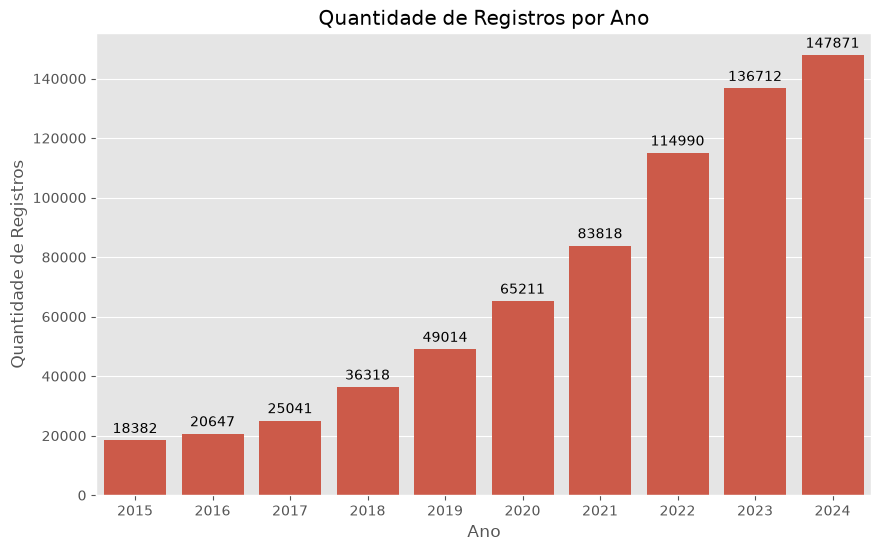

In [8]:
plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=df,
    x='ANO_CENSO'
    #hue='MODALIDADE_ENSINO'
)

plt.title('Quantidade de Registros por Ano')
plt.xlabel('Ano')
plt.ylabel('Quantidade de Registros')

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.show()

### Distribuição entre Presencial e EAD

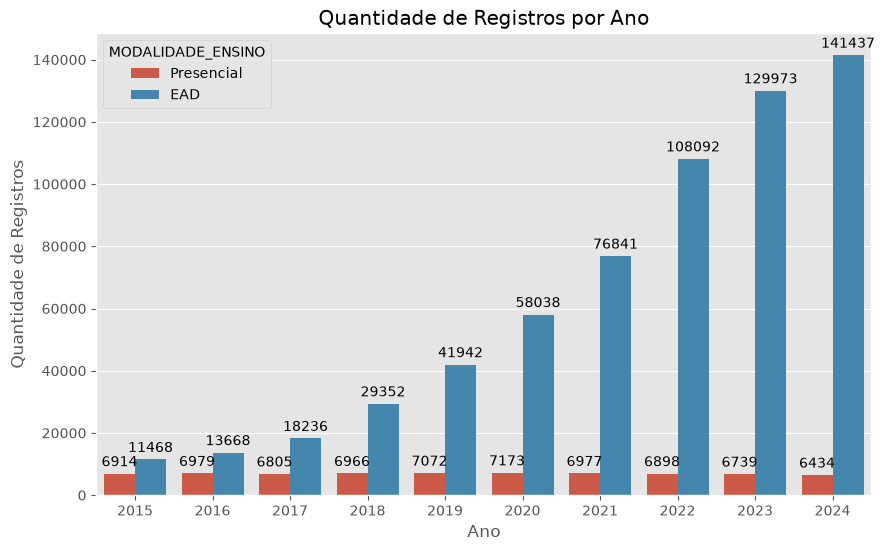

In [9]:
plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=df,
    x='ANO_CENSO',
    hue='MODALIDADE_ENSINO'
)

plt.title('Quantidade de Registros por Ano')
plt.xlabel('Ano')
plt.ylabel('Quantidade de Registros')

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.show()

### Quantidade de IES distintas por ano
- Temos (816) IES distintas na Base de dados com uma media de (553) IES de 2015 á 2024
- IES que oferecem apenas o Ensino Presencial vem caindo, enquanto IES que oferecem EAD ou ambos vem crescendo 
- Das 816 IES distintas apenas 329 fizeram o INEP de 2015 á 2024

In [10]:
# Temos (816) IES distintas e temos um média de (553) por ano
df['COD_IES'].nunique()

816

In [11]:
df_ies_ano = (
    df.groupby('ANO_CENSO')['COD_IES']
      .nunique()
      .reset_index(name='QTD_IES_DISTINTAS')
)
df_ies_ano

,ANO_CENSO,QTD_IES_DISTINTAS
0,2015,524
1,2016,534
2,2017,538
3,2018,553
4,2019,554
5,2020,539
6,2021,567
7,2022,569
8,2023,580
9,2024,573


In [12]:
df_modalidade_ies = (
    df.groupby(['ANO_CENSO', 'COD_IES'])['MODALIDADE_ENSINO']
      .agg(lambda x: set(x.dropna()))
      .reset_index()
)

In [13]:
def classificar_modalidade(modalidades):
    if modalidades == {'Presencial'}:
        return 'Apenas Presencial'
    
    elif modalidades == {'EAD'}:
        return 'Apenas EAD'
    
    elif 'Presencial' in modalidades and 'EAD' in modalidades:
        return 'Presencial e EAD'
    
    else:
        return 'Outros'

df_modalidade_ies['TIPO_IES'] = (
    df_modalidade_ies['MODALIDADE_ENSINO']
    .apply(classificar_modalidade)
)

In [14]:
df_resumo = (
    df_modalidade_ies
    .groupby(['ANO_CENSO', 'TIPO_IES'])
    .size()
    .reset_index(name='QTD_IES')
)

df_resumo

,ANO_CENSO,TIPO_IES,QTD_IES
0,2015,Apenas EAD,24
1,2015,Apenas Presencial,469
2,2015,Presencial e EAD,31
3,2016,Apenas EAD,25
4,2016,Apenas Presencial,469
5,2016,Presencial e EAD,40
6,2017,Apenas EAD,29
7,2017,Apenas Presencial,461
8,2017,Presencial e EAD,48
9,2018,Apenas EAD,48


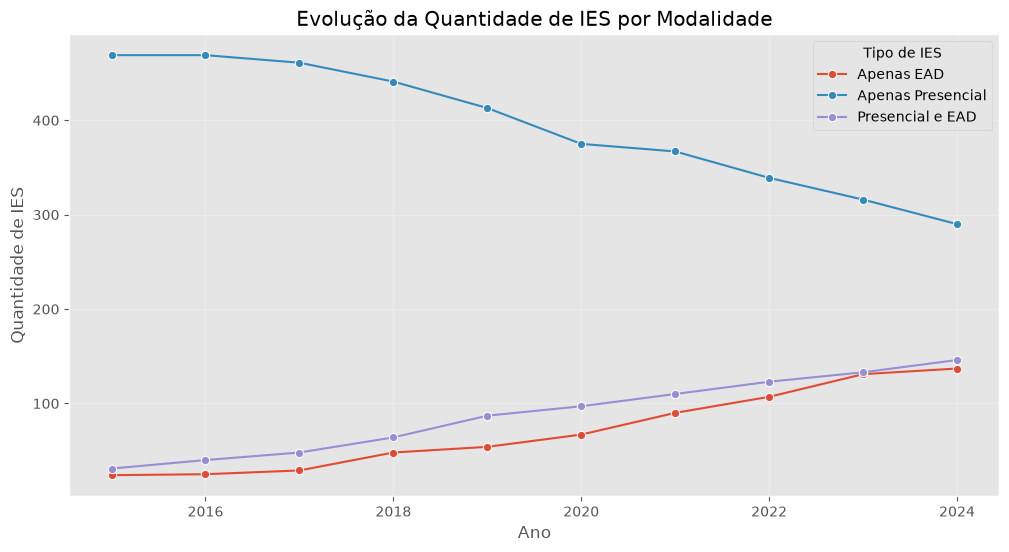

In [15]:
'''
Pode verificar que IES que tem suas grades apenas Presencial vem caindo ao longo do tempo
Enquanto IES curso EAD e EAD/ Presencial vem crescendo
'''
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df_resumo,
    x='ANO_CENSO',
    y='QTD_IES',
    hue='TIPO_IES',
    marker='o'
)

plt.title('Evolução da Quantidade de IES por Modalidade')
plt.xlabel('Ano')
plt.ylabel('Quantidade de IES')

plt.legend(title='Tipo de IES')
plt.grid(True, alpha=0.3)

plt.show()

In [16]:
# Quantidade total de anos existentes na base
qtd_anos = df['ANO_CENSO'].nunique()

qtd_anos

ies_por_ano = (
    df.groupby('COD_IES')['ANO_CENSO']
      .nunique()
      .reset_index(name='QTD_ANOS')
)

ies_por_ano.head()

,COD_IES,QTD_ANOS
0,14,4
1,19,10
2,21,2
3,22,10
4,68,8


In [17]:
ies_todos_anos = ies_por_ano[
    ies_por_ano['QTD_ANOS'] == qtd_anos
]

ies_todos_anos

,COD_IES,QTD_ANOS
1,19,10
3,22,10
5,109,10
6,124,10
7,125,10
...,...,...
619,17014,10
622,17355,10
631,17690,10
632,17691,10


In [18]:
anos_analise = [2015,2016,2017,2018,2019, 2020, 2021, 2022, 2023, 2024]

df_periodo = df[
    df['ANO_CENSO'].isin(anos_analise)
]

ies_qtd_anos = (
    df_periodo
    .groupby('COD_IES')['ANO_CENSO']
    .nunique()
    .reset_index(name='QTD_ANOS')
)

ies_fora_grupo = ies_qtd_anos[
    ies_qtd_anos['QTD_ANOS'] < len(anos_analise)
]

ies_fora_grupo

,COD_IES,QTD_ANOS
0,14,4
2,21,2
4,68,8
8,131,5
20,170,5
...,...,...
811,26376,1
812,26400,2
813,26543,1
814,26719,1


In [19]:

# Filtrar período e modalidade presencial
df_presencial = df[
    (df['ANO_CENSO'].isin(anos_analise)) &
    (df['MODALIDADE_ENSINO'] == 'Presencial')
].copy()

# Contar em quantos anos cada IES aparece
ies_todos_anos_presencial = (
    df_presencial
    .groupby('COD_IES')['ANO_CENSO']
    .nunique()
    .reset_index(name='QTD_ANOS')
)

# Manter somente as IES presentes em todos os anos
ies_todos_anos_presencial = ies_todos_anos_presencial[
    ies_todos_anos_presencial['QTD_ANOS'] == len(anos_analise)
]

ies_todos_anos_presencial

,COD_IES,QTD_ANOS
0,19,10
1,22,10
3,109,10
4,124,10
5,125,10
...,...,...
509,17014,10
511,17355,10
519,17690,10
520,17691,10


In [20]:
# Será utilizada para o filtro de IES que fizeram o INEP de 2015 á 2024
lista_ies_presencial_todos_anos = ies_todos_anos_presencial['COD_IES'].tolist()
lista_ies_presencial_todos_anos

[19,
 22,
 109,
 124,
 125,
 135,
 137,
 138,
 146,
 150,
 151,
 161,
 162,
 167,
 200,
 203,
 207,
 208,
 213,
 219,
 221,
 222,
 224,
 226,
 227,
 231,
 234,
 242,
 244,
 263,
 265,
 266,
 269,
 271,
 275,
 276,
 316,
 319,
 322,
 346,
 360,
 361,
 362,
 363,
 368,
 370,
 371,
 373,
 374,
 375,
 376,
 415,
 416,
 417,
 420,
 434,
 438,
 439,
 440,
 456,
 458,
 461,
 466,
 481,
 483,
 491,
 493,
 496,
 502,
 517,
 521,
 526,
 546,
 636,
 652,
 670,
 672,
 707,
 716,
 734,
 737,
 738,
 790,
 793,
 852,
 898,
 905,
 910,
 922,
 923,
 952,
 953,
 997,
 1032,
 1043,
 1045,
 1046,
 1048,
 1092,
 1096,
 1100,
 1122,
 1129,
 1144,
 1149,
 1161,
 1182,
 1187,
 1195,
 1219,
 1221,
 1224,
 1225,
 1230,
 1266,
 1270,
 1273,
 1276,
 1279,
 1281,
 1286,
 1290,
 1294,
 1299,
 1300,
 1301,
 1307,
 1310,
 1311,
 1313,
 1317,
 1322,
 1345,
 1355,
 1365,
 1386,
 1388,
 1412,
 1418,
 1432,
 1434,
 1438,
 1444,
 1445,
 1456,
 1476,
 1478,
 1490,
 1497,
 1499,
 1502,
 1520,
 1526,
 1541,
 1545,
 1554,
 15

### Quantidade de cursos distintos
- Há 16.485 cursos distintos
- O crescimento de Novos Cursos Presencial se mantiveram e o Cursos EAD tiveram um crescimento exponencial ao longo dos anos de 2015 á 2024
- CAGR (Compound Annual Growth Rate) é a Taxa de Crescimento Anual Compost para Cursos Presencial (-0,80%) e EAD (26,47%)

In [21]:
df['COD_CURSO'].nunique()

16485

In [22]:
df_qtd_cursos = (
    df.groupby('ANO_CENSO')['COD_CURSO']
      .nunique()
      .reset_index(name='QTD_CURSOS_DISTINTOS')
)

df_qtd_cursos

,ANO_CENSO,QTD_CURSOS_DISTINTOS
0,2015,7619
1,2016,7790
2,2017,7785
3,2018,8402
4,2019,9308
5,2020,10193
6,2021,10905
7,2022,11721
8,2023,12316
9,2024,12271


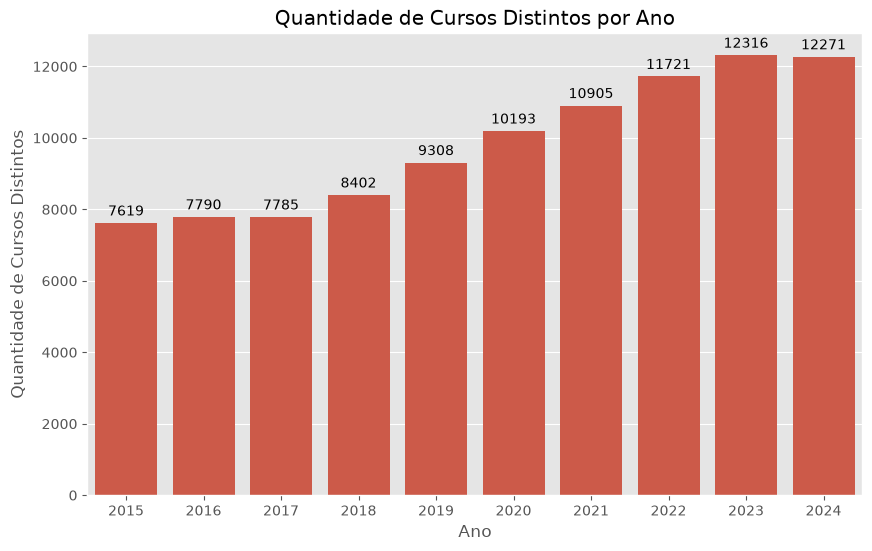

In [23]:
# QUantidade de cursos distintos por ano
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=df_qtd_cursos,
    x='ANO_CENSO',
    y='QTD_CURSOS_DISTINTOS'
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Quantidade de Cursos Distintos por Ano')
plt.xlabel('Ano')
plt.ylabel('Quantidade de Cursos Distintos')

plt.show()

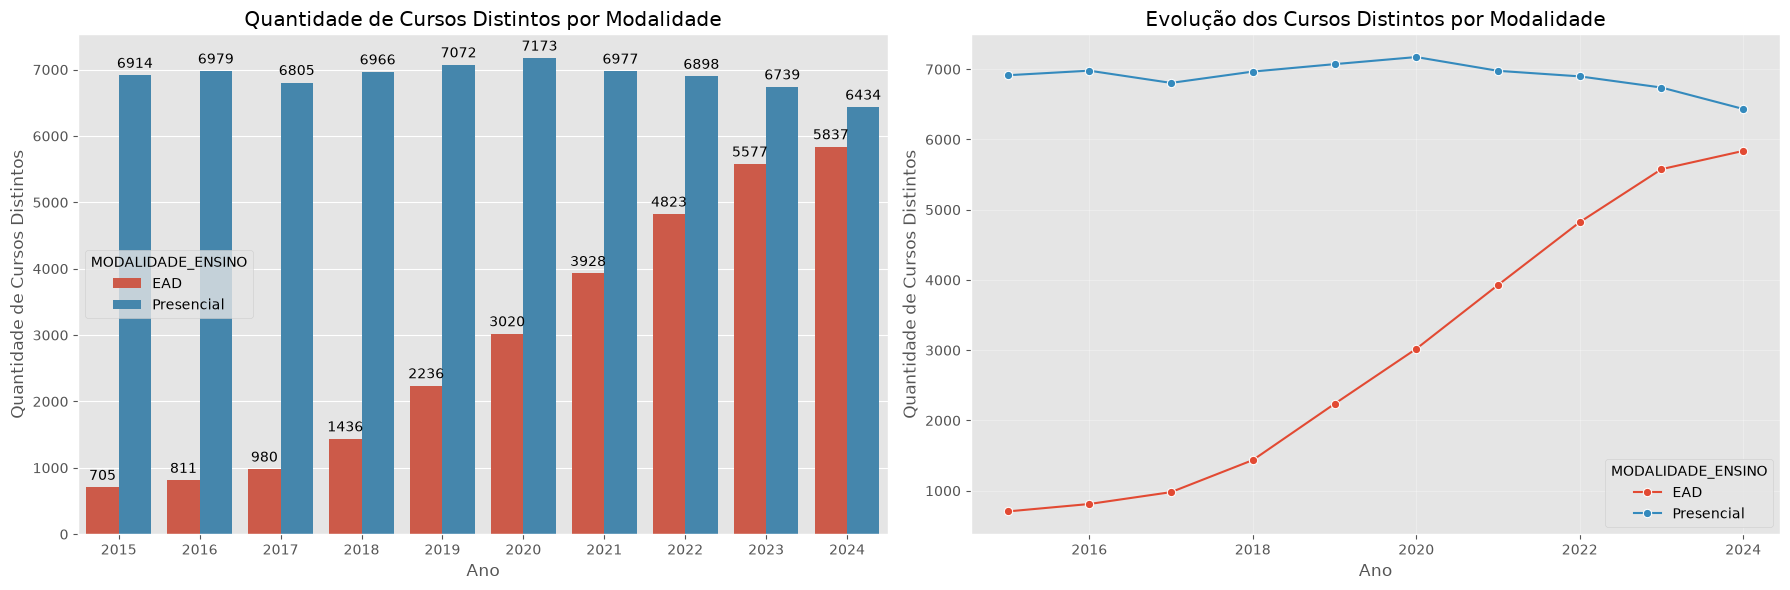

In [24]:
# Preparar os dados
df_cursos_modalidade = (
    df[
        df['MODALIDADE_ENSINO'].isin(['Presencial', 'EAD'])
    ]
    .groupby(
        ['ANO_CENSO', 'MODALIDADE_ENSINO']
    )['COD_CURSO']
    .nunique()
    .reset_index(name='QTD_CURSOS_DISTINTOS')
)

# Criar os subplots
fig, axes = plt.subplots(
    1, 2,
    figsize=(18, 6)
)

# ==========================
# GRÁFICO 1 - BARRAS
# ==========================

sns.barplot(
    data=df_cursos_modalidade,
    x='ANO_CENSO',
    y='QTD_CURSOS_DISTINTOS',
    hue='MODALIDADE_ENSINO',
    ax=axes[0]
)

axes[0].set_title(
    'Quantidade de Cursos Distintos por Modalidade'
)

axes[0].set_xlabel('Ano')
axes[0].set_ylabel('Quantidade de Cursos Distintos')

# Valores nas barras
for container in axes[0].containers:
    axes[0].bar_label(
        container,
        padding=3
    )


# ==========================
# GRÁFICO 2 - LINHA
# ==========================

sns.lineplot(
    data=df_cursos_modalidade,
    x='ANO_CENSO',
    y='QTD_CURSOS_DISTINTOS',
    hue='MODALIDADE_ENSINO',
    marker='o',
    ax=axes[1]
)

axes[1].set_title(
    'Evolução dos Cursos Distintos por Modalidade'
)

axes[1].set_xlabel('Ano')
axes[1].set_ylabel('Quantidade de Cursos Distintos')

axes[1].grid(
    alpha=0.3
)

# Ajustar layout
plt.tight_layout()

plt.show()

### Quantidade de municípios
- Há 434 municipios

In [25]:
# Municipios
pd.crosstab(
   df['NOME_MUNICIPIO_CURSO'],
   df['NOME_AREA_GERAL_CINE'],
   margins=True
)

NOME_AREA_GERAL_CINE,"Agricultura, silvicultura, pesca e veterinária",Artes e humanidades,"Ciências naturais, matemática e estatística","Ciências sociais, comunicação e informação",Computação e Tecnologias da Informação e Comunicação (TIC),Educação,"Engenharia, produção e construção","Negócios, administração e direito",Programas básicos,Saúde e bem-estar,Serviços,All
NOME_MUNICIPIO_CURSO,,,,,,,,,,,,
Adamantina,21,57,1,45,107,309,98,396,0,125,93,1252
Aguaí,1,8,2,5,25,74,21,112,0,21,8,277
Agudos,8,44,6,24,78,207,76,345,0,67,45,900
Alfredo Marcondes,0,3,0,2,3,10,1,13,0,2,3,37
Altinópolis,0,7,0,2,2,46,5,54,0,3,5,124
...,...,...,...,...,...,...,...,...,...,...,...,...
Águas de Lindóia,0,8,1,16,38,98,9,129,0,40,21,360
Águas de Santa Bárbara,2,1,0,1,2,3,2,11,0,4,2,28
Águas de São Pedro,0,1,0,0,14,8,2,47,0,0,20,92


### Distribuição por área CINE
- 73% dos registros estão entre as area
- Negócios, administração e direito
- Educação
- Computação e Tecnologias da Informação e Comunicação (TIC)
- Engenharia, produção e construção


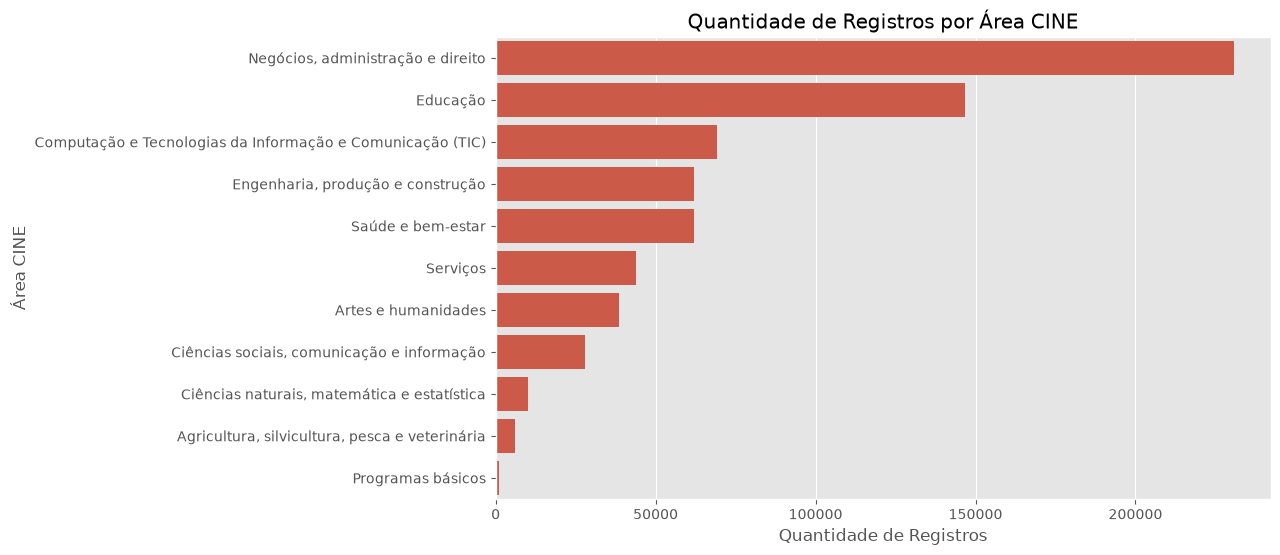

In [26]:
ordem = df['NOME_AREA_GERAL_CINE'].value_counts().index

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    y='NOME_AREA_GERAL_CINE',
    order=ordem
)

plt.title('Quantidade de Registros por Área CINE')
plt.xlabel('Quantidade de Registros')
plt.ylabel('Área CINE')

plt.show()

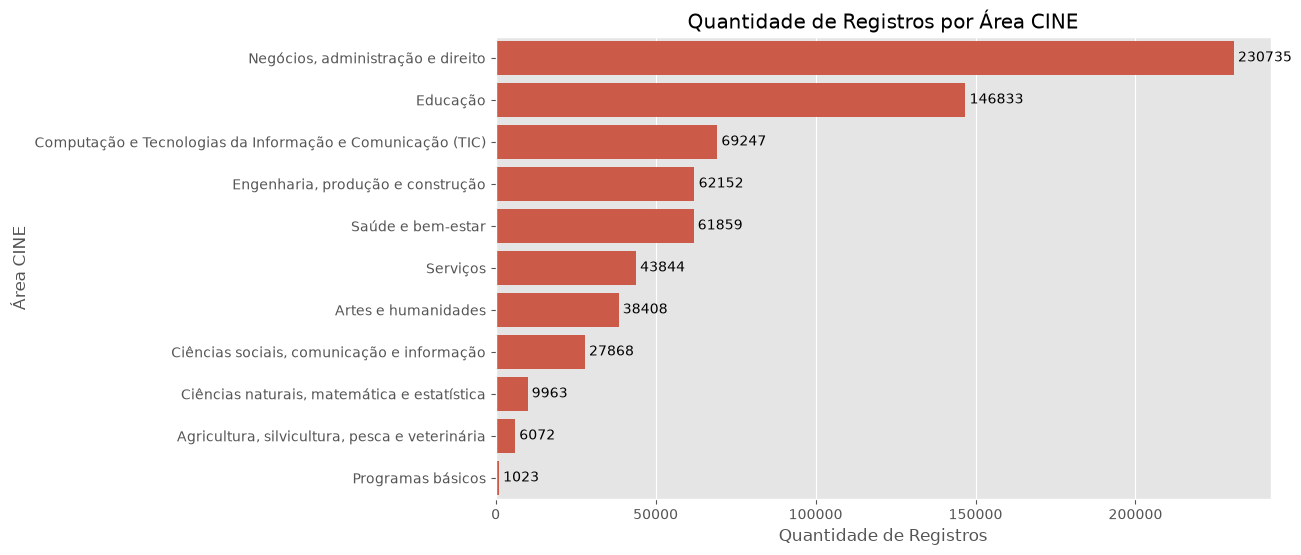

In [27]:
plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=df,
    y='NOME_AREA_GERAL_CINE',
    order=df['NOME_AREA_GERAL_CINE'].value_counts().index
)

ax.bar_label(ax.containers[0], padding=3)

plt.title('Quantidade de Registros por Área CINE')
plt.xlabel('Quantidade de Registros')
plt.ylabel('Área CINE')

plt.show()

### Evolução das vagas

In [28]:
vagas_ano = (
    df.groupby('ANO_CENSO', as_index=False)
      ['QTD_VAGAS_TOTAL']
      .sum()
)

vagas_ano

,ANO_CENSO,QTD_VAGAS_TOTAL
0,2015,1820013
1,2016,1742093
2,2017,1679674
3,2018,1706852
4,2019,1540287
5,2020,1636114
6,2021,1530822
7,2022,1430285
8,2023,1327281
9,2024,1130103


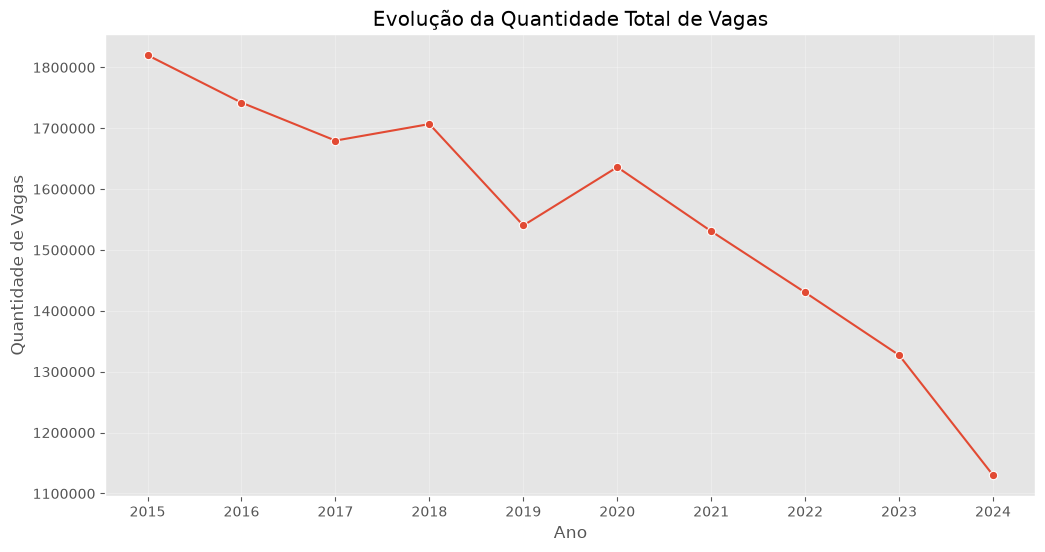

In [30]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=vagas_ano,
    x='ANO_CENSO',
    y='QTD_VAGAS_TOTAL',
    marker='o',
    errorbar=None
)

plt.title('Evolução da Quantidade Total de Vagas')
plt.xlabel('Ano')
plt.ylabel('Quantidade de Vagas')

plt.xticks(vagas_ano['ANO_CENSO'])

plt.ticklabel_format(
    style='plain',
    axis='y'
)

plt.grid(alpha=0.3)

plt.show()

### Evolução das inscrições

In [31]:
incricoes_ano = (
    df.groupby('ANO_CENSO', as_index=False)
      ['QTD_INSCRICOES_VAGAS_NOVAS']
      .sum()
)

incricoes_ano

,ANO_CENSO,QTD_INSCRICOES_VAGAS_NOVAS
0,2015,1664230
1,2016,2031797
2,2017,2307052
3,2018,2332505
4,2019,2370027
5,2020,1978578
6,2021,1232179
7,2022,1383161
8,2023,1335043
9,2024,1198464


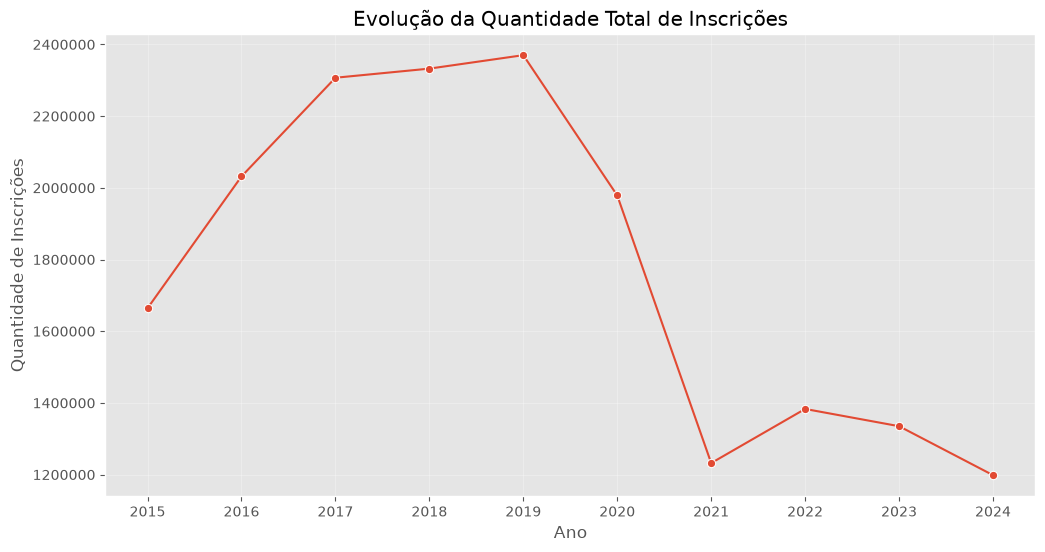

In [32]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=incricoes_ano,
    x='ANO_CENSO',
    y='QTD_INSCRICOES_VAGAS_NOVAS',
    marker='o',
    errorbar=None
)

plt.title('Evolução da Quantidade Total de Inscrições')
plt.xlabel('Ano')
plt.ylabel('Quantidade de Inscrições')

plt.xticks(incricoes_ano['ANO_CENSO'])

plt.ticklabel_format(
    style='plain',
    axis='y'
)

plt.grid(alpha=0.3)

plt.show()

### Evolução dos ingressantes

In [33]:
ingressantes_ano = (
    df.groupby('ANO_CENSO', as_index=False)
      ['QTD_INGRESSANTES_TOTAL']
      .sum()
)

ingressantes_ano

,ANO_CENSO,QTD_INGRESSANTES_TOTAL
0,2015,690852
1,2016,739914
2,2017,760084
3,2018,797943
4,2019,847652
5,2020,890724
6,2021,900855
7,2022,1125158
8,2023,1157841
9,2024,1215682


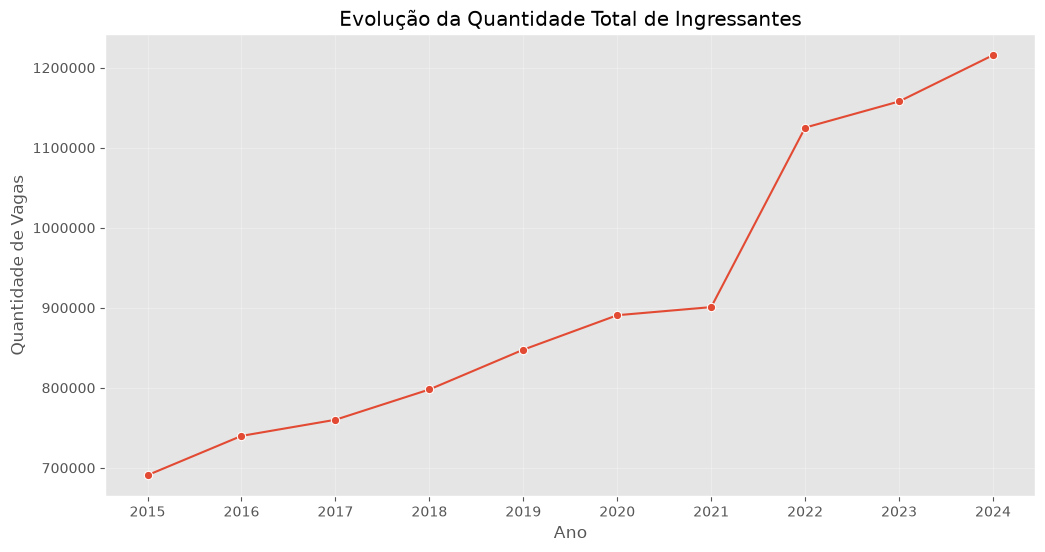

In [34]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=ingressantes_ano,
    x='ANO_CENSO',
    y='QTD_INGRESSANTES_TOTAL',
    marker='o',
    errorbar=None
)

plt.title('Evolução da Quantidade Total de Ingressantes')
plt.xlabel('Ano')
plt.ylabel('Quantidade de Vagas')

plt.xticks(incricoes_ano['ANO_CENSO'])

plt.ticklabel_format(
    style='plain',
    axis='y'
)

plt.grid(alpha=0.3)

plt.show()

### Evolução dos concluintes

In [35]:
concluintes_ano = (
    df.groupby('ANO_CENSO', as_index=False)
      ['QTD_CONCLUINTES']
      .sum()
)

concluintes_ano

,ANO_CENSO,QTD_CONCLUINTES
0,2015,282704
1,2016,281239
2,2017,277340
3,2018,290316
4,2019,276444
5,2020,315662
6,2021,315704
7,2022,295778
8,2023,312838
9,2024,303835


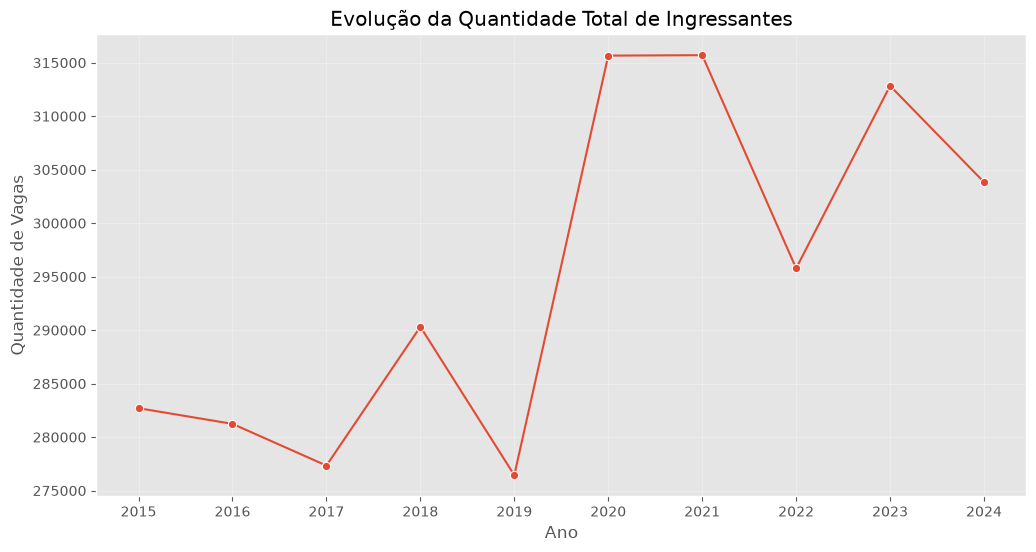

In [36]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=concluintes_ano,
    x='ANO_CENSO',
    y='QTD_CONCLUINTES',
    marker='o',
    errorbar=None
)

plt.title('Evolução da Quantidade Total de Ingressantes')
plt.xlabel('Ano')
plt.ylabel('Quantidade de Vagas')

plt.xticks(concluintes_ano['ANO_CENSO'])

plt.ticklabel_format(
    style='plain',
    axis='y'
)

plt.grid(alpha=0.3)

plt.show()

### Distribuição dos financiamentos estudantis

In [ ]:
df.columns

Index(['ANO_CENSO', 'COD_IES', 'NOME_IES', 'SIGLA_IES',
       'ORGANIZACAO_ACADEMICA', 'COD_REDE', 'COD_CURSO', 'NOME_CURSO',
       'COD_MUNICIPIO', 'NOME_MUNICIPIO_CURSO', 'SIGLA_UF_CURSO', 'COD_CINE',
       'NOME_AREA_GERAL_CINE', 'MODALIDADE_ENSINO', 'GRAU_ACADEMICO',
       'QTD_CURSOS', 'QTD_VAGAS_TOTAL', 'QTD_VAGAS_NOVAS',
       'QTD_INSCRICOES_VAGAS_NOVAS', 'QTD_INGRESSANTES_TOTAL',
       'QTD_INGRESSANTES_VAGAS_NOVAS', 'QTD_INGRESSANTES_FEMININO',
       'QTD_INGRESSANTES_MASCULINO', 'QTD_CONCLUINTES', 'QTD_FIES',
       'QTD_PROUNI', 'QTD_FINANCIAMENTO'],
      dtype='str')

<Axes: xlabel='QTD_FINANCIAMENTO', ylabel='Count'>

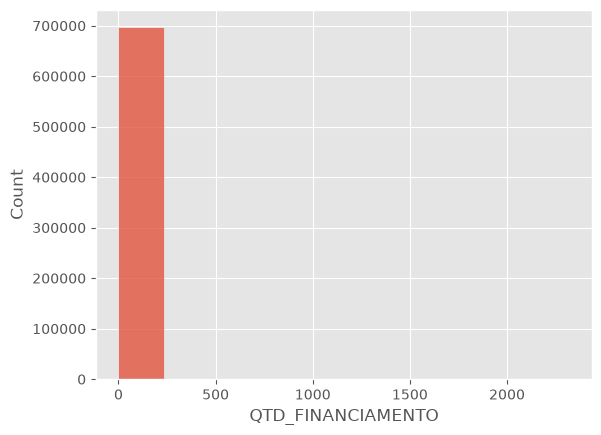

In [ ]:
sns.histplot(
   df['QTD_FINANCIAMENTO'],
   bins=10
)

<Axes: xlabel='QTD_FIES', ylabel='Count'>

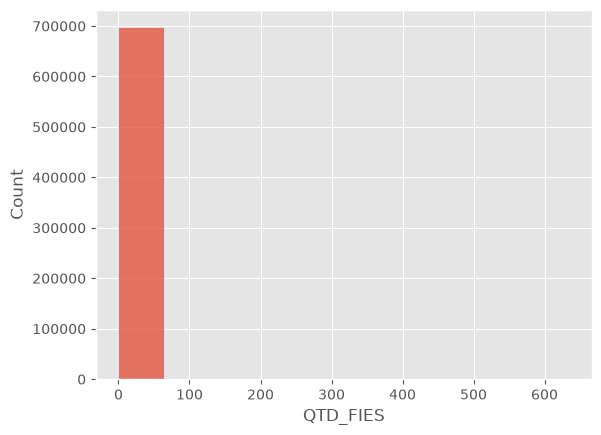

In [ ]:
sns.histplot(
   df['QTD_FIES'],
   bins=10
)

<Axes: xlabel='QTD_PROUNI', ylabel='Count'>

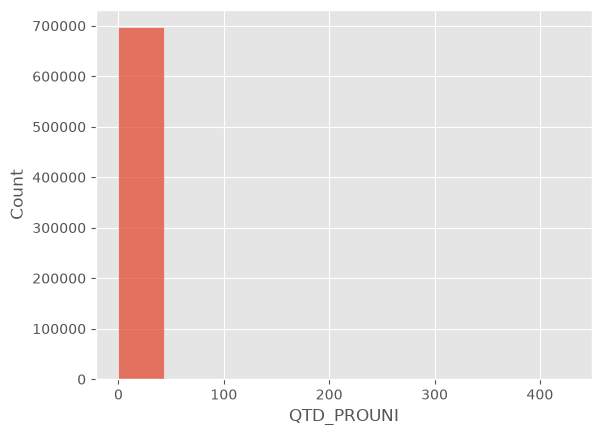

In [ ]:
sns.histplot(
   df['QTD_PROUNI'],
   bins=10
)

In [ ]:
# Correlações de quantidades observadas (não incluir identificadores como códigos numéricos)
colunas_metricas_eda = [
    'QTD_VAGAS_TOTAL', 'QTD_VAGAS_NOVAS',
    'QTD_INSCRICOES_VAGAS_NOVAS', 'QTD_INGRESSANTES_TOTAL',
    'QTD_INGRESSANTES_VAGAS_NOVAS', 'QTD_CONCLUINTES',
    'QTD_FIES', 'QTD_PROUNI', 'QTD_FINANCIAMENTO'
]
corr = df[colunas_metricas_eda].corr(numeric_only=True)
display(corr.round(3))


In [ ]:
# Correlação é DESCRITIVA e não permite inferir causalidade nem poder preditivo em t+1.
plt.figure(figsize=(11, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlações entre indicadores quantitativos (EDA)')
plt.tight_layout()
plt.show()


## 2.9 Relação Presencial x EAD

Uma análise específica será realizada para compreender como a evolução do EAD se relaciona com o comportamento do ensino presencial.

Serão comparadas, por ano:

- vagas Presencial x EAD;
- inscrições Presencial x EAD;
- ingressantes Presencial x EAD;
- taxa de ocupação/aproveitamento;
- participação de cada modalidade no total de ingressantes;
- evolução por área de formação;
- evolução por município.

O objetivo é investigar se o crescimento do EAD está associado a uma redistribuição da demanda anteriormente concentrada no ensino presencial.

In [ ]:
modalidade_ano = (
    df.groupby(
        ['ANO_CENSO', 'MODALIDADE_ENSINO'],
        as_index=False
    )
    .agg(
        VAGAS_TOTAL=('QTD_VAGAS_TOTAL', 'sum'),
        VAGAS_NOVAS=('QTD_VAGAS_NOVAS', 'sum'),
        INSCRICOES=('QTD_INSCRICOES_VAGAS_NOVAS', 'sum'),
        INGRESSANTES=('QTD_INGRESSANTES_VAGAS_NOVAS', 'sum')
    )
)

modalidade_ano.head()

,ANO_CENSO,MODALIDADE_ENSINO,VAGAS_TOTAL,VAGAS_NOVAS,INSCRICOES,INGRESSANTES
0,2015,EAD,0,0,0,125916
1,2015,Presencial,1820013,1203986,1664230,489819
2,2016,EAD,0,0,0,172780
3,2016,Presencial,1742093,1226203,2031797,488056
4,2017,EAD,0,0,0,197304


### Vagas Presencial x EAD

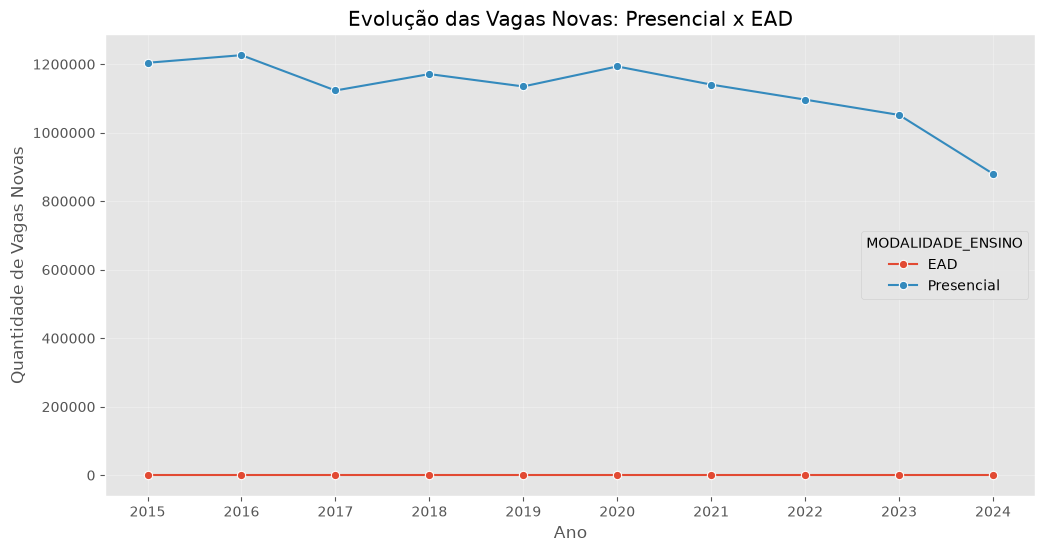

In [ ]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=modalidade_ano,
    x='ANO_CENSO',
    y='VAGAS_NOVAS',
    hue='MODALIDADE_ENSINO',
    marker='o'
)

plt.title('Evolução das Vagas Novas: Presencial x EAD')
plt.xlabel('Ano')
plt.ylabel('Quantidade de Vagas Novas')
plt.xticks(sorted(modalidade_ano['ANO_CENSO'].unique()))
plt.ticklabel_format(style='plain', axis='y')
plt.grid(alpha=0.3)

plt.show()

### Inscrições Presencial x EAD

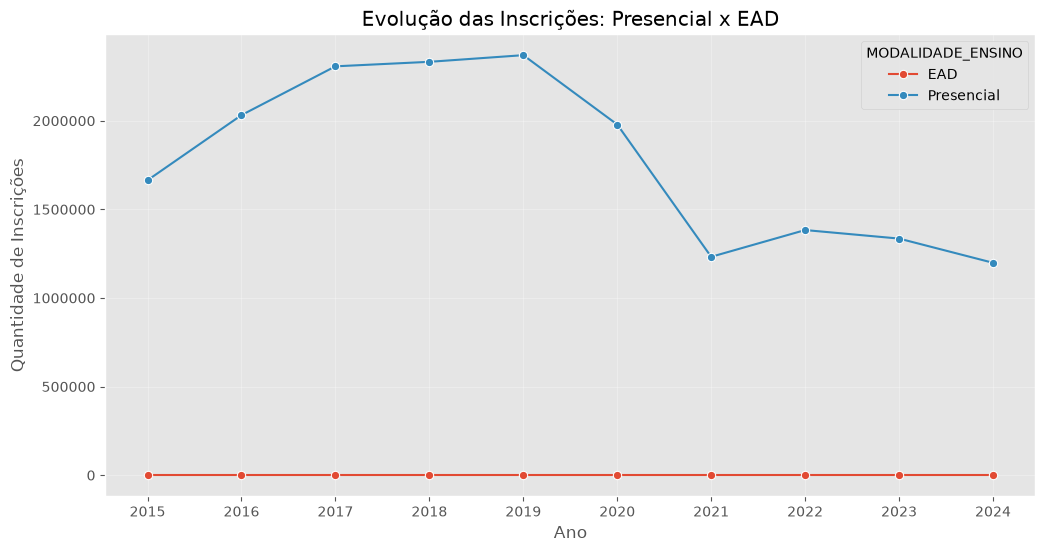

In [ ]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=modalidade_ano,
    x='ANO_CENSO',
    y='INSCRICOES',
    hue='MODALIDADE_ENSINO',
    marker='o'
)

plt.title('Evolução das Inscrições: Presencial x EAD')
plt.xlabel('Ano')
plt.ylabel('Quantidade de Inscrições')
plt.xticks(sorted(modalidade_ano['ANO_CENSO'].unique()))
plt.ticklabel_format(style='plain', axis='y')
plt.grid(alpha=0.3)

plt.show()

### Ingressantes Presencial x EAD

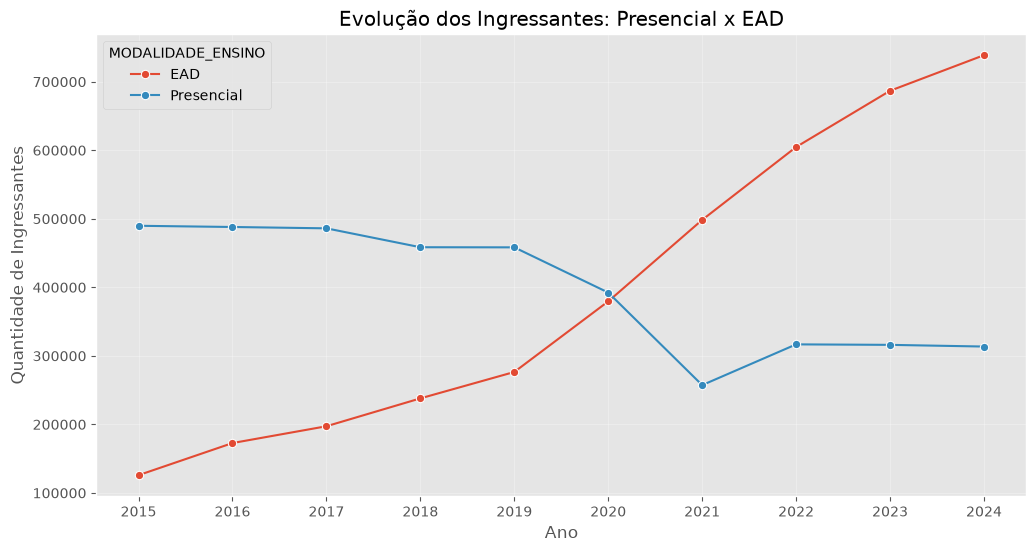

In [ ]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=modalidade_ano,
    x='ANO_CENSO',
    y='INGRESSANTES',
    hue='MODALIDADE_ENSINO',
    marker='o'
)

plt.title('Evolução dos Ingressantes: Presencial x EAD')
plt.xlabel('Ano')
plt.ylabel('Quantidade de Ingressantes')
plt.xticks(sorted(modalidade_ano['ANO_CENSO'].unique()))
plt.ticklabel_format(style='plain', axis='y')
plt.grid(alpha=0.3)

plt.show()

### Taxa de aproveitamento: diagnóstico contextual (Presencial × EAD)

`Ingressantes por vagas novas ÷ vagas novas × 100`, **somente quando o denominador for maior que zero**. É uma **taxa de aproveitamento aparente**, não equivale necessariamente à ocupação física de salas/turmas. Nos primeiros anos, parte dos registros EAD pode apresentar vagas/inscrições zeradas e ingressantes positivos: isso demanda validação de comparabilidade entre layouts/anos, e não significa ocupação infinita ou 100%. Além disso, uma razão superior a 100% precisa ser investigada — não é automaticamente erro.


In [ ]:
# Evitar divisão por zero. Ausência/zero de vagas não recebe taxa artificial.
modalidade_ano['TAXA_APROVEITAMENTO'] = np.where(
    modalidade_ano['VAGAS_NOVAS'] > 0,
    modalidade_ano['INGRESSANTES'] / modalidade_ano['VAGAS_NOVAS'] * 100,
    np.nan
)
modalidade_ano['ALERTA_INCONSISTENCIA'] = np.where(
    (modalidade_ano['VAGAS_NOVAS'] == 0) & (modalidade_ano['INGRESSANTES'] > 0),
    'Ingressantes > 0 com vagas novas = 0: verificar fonte/layout',
    ''
)
display(modalidade_ano[
    ['ANO_CENSO', 'MODALIDADE_ENSINO', 'VAGAS_NOVAS', 'INGRESSANTES',
     'TAXA_APROVEITAMENTO', 'ALERTA_INCONSISTENCIA']
])


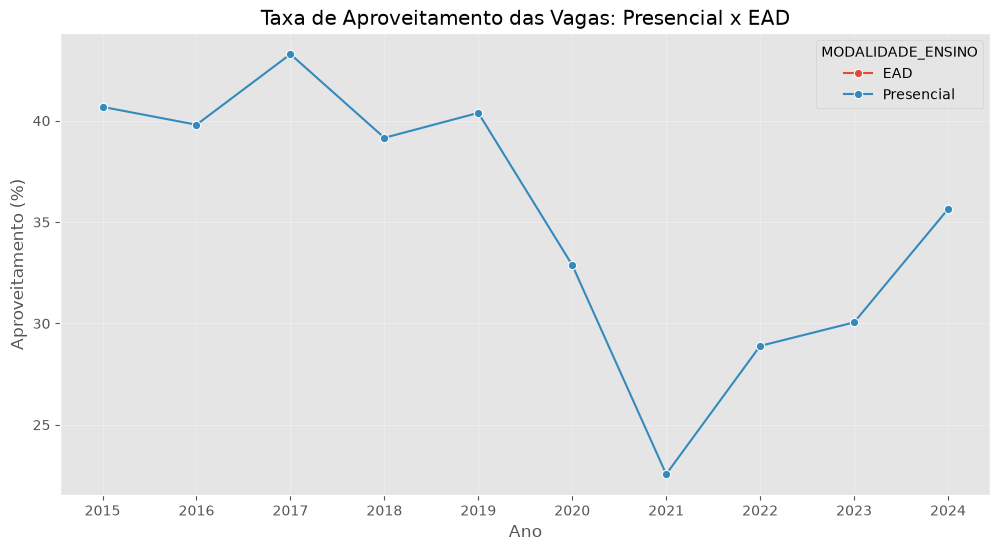

In [ ]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=modalidade_ano,
    x='ANO_CENSO',
    y='TAXA_APROVEITAMENTO',
    hue='MODALIDADE_ENSINO',
    marker='o'
)

plt.title('Taxa de Aproveitamento das Vagas: Presencial x EAD')
plt.xlabel('Ano')
plt.ylabel('Aproveitamento (%)')
plt.xticks(sorted(modalidade_ano['ANO_CENSO'].unique()))
plt.grid(alpha=0.3)

plt.show()

### Participação de cada modalidade no total de ingressantes

In [ ]:
modalidade_ano['TOTAL_INGRESSANTES_ANO'] = (
    modalidade_ano
    .groupby('ANO_CENSO')['INGRESSANTES']
    .transform('sum')
)

In [ ]:
modalidade_ano['SHARE_INGRESSANTES'] = (
    modalidade_ano['INGRESSANTES']
    / modalidade_ano['TOTAL_INGRESSANTES_ANO']
    * 100
)

In [ ]:
modalidade_ano[
    [
        'ANO_CENSO',
        'MODALIDADE_ENSINO',
        'INGRESSANTES',
        'SHARE_INGRESSANTES'
    ]
]

,ANO_CENSO,MODALIDADE_ENSINO,INGRESSANTES,SHARE_INGRESSANTES
0,2015,EAD,125916,20.449706
1,2015,Presencial,489819,79.550294
2,2016,EAD,172780,26.145670
3,2016,Presencial,488056,73.854330
4,2017,EAD,197304,28.870897
5,2017,Presencial,486097,71.129103
6,2018,EAD,237971,34.167279
7,2018,Presencial,458517,65.832721
8,2019,EAD,276492,37.626508
9,2019,Presencial,458341,62.373492


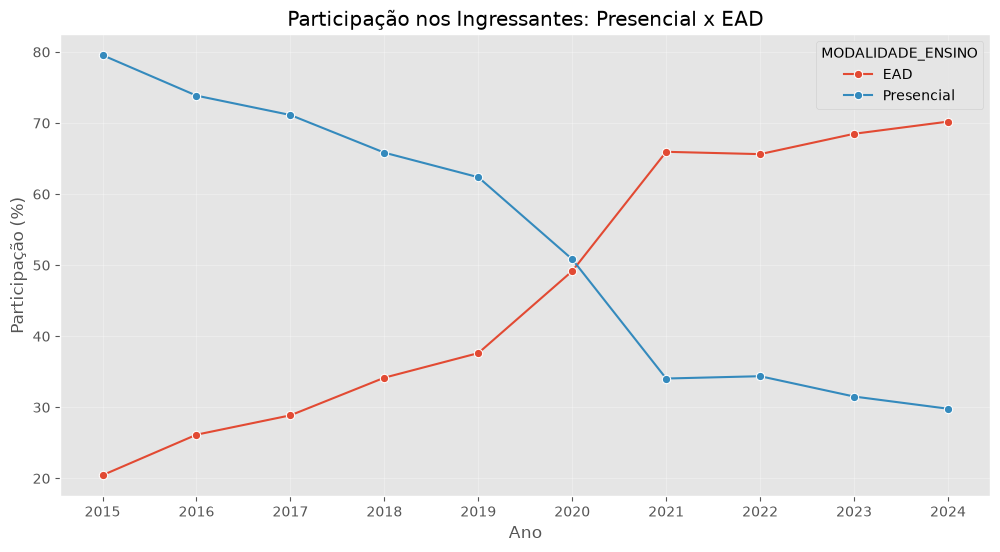

In [ ]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=modalidade_ano,
    x='ANO_CENSO',
    y='SHARE_INGRESSANTES',
    hue='MODALIDADE_ENSINO',
    marker='o'
)

plt.title('Participação nos Ingressantes: Presencial x EAD')
plt.xlabel('Ano')
plt.ylabel('Participação (%)')
plt.xticks(sorted(modalidade_ano['ANO_CENSO'].unique()))
plt.grid(alpha=0.3)

plt.show()

### Evolução por área de formação

In [ ]:
area_modalidade = (
    df.groupby(
        [
            'ANO_CENSO',
            'NOME_AREA_GERAL_CINE',
            'MODALIDADE_ENSINO'
        ],
        as_index=False
    )
    .agg(
        VAGAS=('QTD_VAGAS_NOVAS', 'sum'),
        INGRESSANTES=('QTD_INGRESSANTES_VAGAS_NOVAS', 'sum')
    )
)

In [ ]:
area = 'Computação e Tecnologias da Informação e Comunicação (TIC)'

df_area = area_modalidade[
    area_modalidade['NOME_AREA_GERAL_CINE'] == area
]

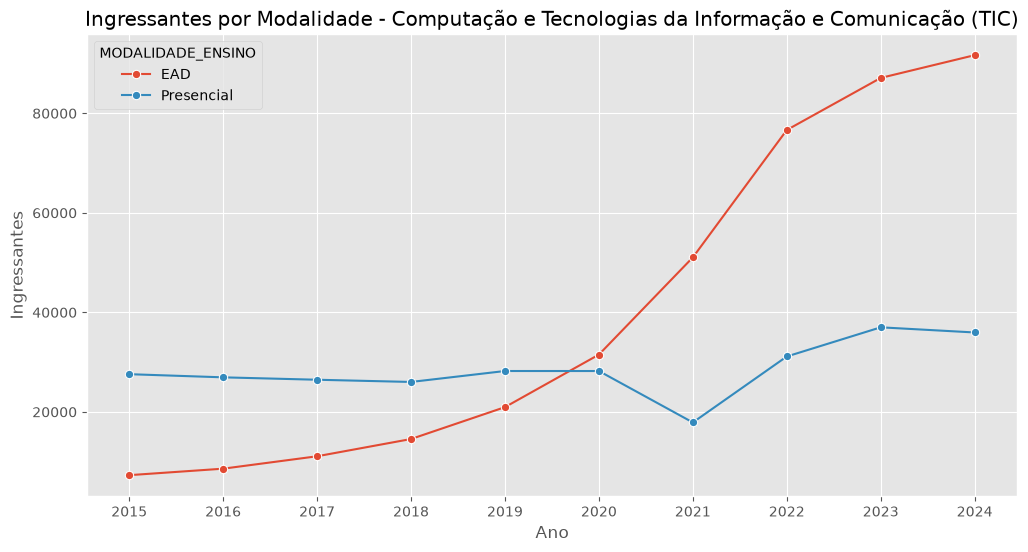

In [ ]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df_area,
    x='ANO_CENSO',
    y='INGRESSANTES',
    hue='MODALIDADE_ENSINO',
    marker='o'
)

plt.title(f'Ingressantes por Modalidade - {area}')
plt.xlabel('Ano')
plt.ylabel('Ingressantes')
plt.xticks(sorted(df_area['ANO_CENSO'].unique()))
plt.ticklabel_format(style='plain', axis='y')

plt.show()

### Evolução por município

In [ ]:
municipio_modalidade = (
    df.groupby(
        [
            'ANO_CENSO',
            'NOME_MUNICIPIO_CURSO',
            'MODALIDADE_ENSINO'
        ],
        as_index=False
    )
    .agg(
        VAGAS=('QTD_VAGAS_NOVAS', 'sum'),
        INGRESSANTES=('QTD_INGRESSANTES_VAGAS_NOVAS', 'sum')
    )
)

In [ ]:
sp = municipio_modalidade[
    municipio_modalidade['NOME_MUNICIPIO_CURSO'] == 'São Paulo'
]

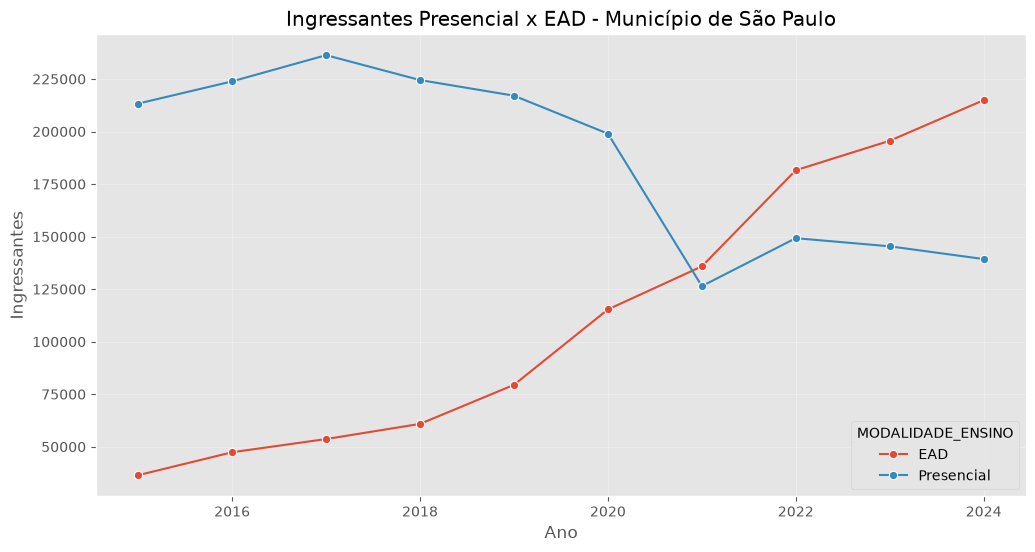

In [ ]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=sp,
    x='ANO_CENSO',
    y='INGRESSANTES',
    hue='MODALIDADE_ENSINO',
    marker='o'
)

plt.title('Ingressantes Presencial x EAD - Município de São Paulo')
plt.xlabel('Ano')
plt.ylabel('Ingressantes')
plt.ticklabel_format(style='plain', axis='y')
plt.grid(alpha=0.3)

plt.show()

## 2.10 Possíveis Features Derivadas — apenas planejamento

As variáveis abaixo são **planejadas para o ano-alvo `t+1`**, sempre com valores observados **até `t`**:

- `INGRESSANTES_LAG_1`: ingressantes observados em `t` (último ano antes do alvo).
- `INGRESSANTES_LAG_2`: ingressantes em `t−1`.
- `MEDIA_INGRESSANTES_3_ANOS`: média dos ingressantes de `t`, `t−1` e `t−2` (apenas histórico completo).
- `CRESCIMENTO_INGRESSANTES`: variação de `t−1` para `t`, sem divisão por zero.
- `VAGAS_LAG_1`, `INSCRICOES_LAG_1`: oferta e inscrições observadas em `t`.
- `TAXA_OCUPACAO_LAG_1`, `RELACAO_INSCRICOES_VAGAS_LAG_1`: razões calculadas com valores de `t`, quando vagas > 0.
- `FIES_LAG_1`, `PROUNI_LAG_1`, `FINANCIAMENTO_LAG_1`: séries históricas de acesso/financiamento, opcionais.

Indicadores exploratórios *do mesmo ano observado*, como vagas potencialmente ociosas, aproveitamento, participação feminina e financiamento, não serão usados diretamente para prever esse mesmo ano. As versões históricas podem ser avaliadas, desde que a informação estivesse disponível na data real da previsão.


## 2.11 Análise de Outliers

A avaliação considera `QTD_VAGAS_TOTAL`, `QTD_VAGAS_NOVAS`, `QTD_INSCRICOES_VAGAS_NOVAS`, `QTD_INGRESSANTES_TOTAL`, `QTD_INGRESSANTES_VAGAS_NOVAS` e `QTD_CONCLUINTES`. Serão examinados percentis, regra do IQR e boxplots, com contexto por área CINE e ano.

**Critério de decisão:** IES ou cursos grandes podem gerar extremos legítimos. A contagem IQR **não é motivo de remoção automática**; toda correção, winsorização ou exclusão exige justificativa de domínio e deve ser documentada. Valores negativos representam inconsistência potencial, a verificar na fonte.


In [ ]:
# Estatísticas descritivas robustas: os resultados pertencem à base exploratória (Presencial + EAD)
cols_outliers = [
    'QTD_VAGAS_TOTAL', 'QTD_VAGAS_NOVAS', 'QTD_INSCRICOES_VAGAS_NOVAS',
    'QTD_INGRESSANTES_TOTAL', 'QTD_INGRESSANTES_VAGAS_NOVAS',
    'QTD_CONCLUINTES'
]
resumo_outliers = df[cols_outliers].describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.95, 0.99]
).T
resumo_outliers['IQR'] = resumo_outliers['75%'] - resumo_outliers['25%']
resumo_outliers['LIMITE_SUP_IQR'] = resumo_outliers['75%'] + 1.5 * resumo_outliers['IQR']
# Se o IQR é zero, a regra sinalizaria TODO valor > 0 sem utilidade analítica.
# Nesse cenário usar diagnóstico dos positivos, sem aplicar o limiar IQR.
resumo_outliers['PCT_ZEROS'] = [(df[c].eq(0).mean() * 100).round(2) for c in cols_outliers]
resumo_outliers['QTD_ACIMA_IQR'] = [
    int((df[c] > resumo_outliers.loc[c, 'LIMITE_SUP_IQR']).sum())
    if pd.notna(resumo_outliers.loc[c, 'IQR']) and resumo_outliers.loc[c, 'IQR'] > 0
    else np.nan
    for c in cols_outliers
]
resumo_outliers['PCT_ACIMA_IQR'] = (
    resumo_outliers['QTD_ACIMA_IQR'] / len(df) * 100
).round(2)
resumo_outliers['P99_SO_POSITIVOS'] = [
    df.loc[df[c] > 0, c].quantile(.99) if (df[c] > 0).any() else np.nan
    for c in cols_outliers
]
resumo_outliers['OBSERVACAO'] = np.where(
    resumo_outliers['IQR'].eq(0),
    'IQR=0: observar distribuição positiva; não aplicar regra do IQR',
    'IQR indicativo; sem exclusão automática'
)
display(resumo_outliers)
print('A regra IQR não deve excluir registros automaticamente; métricas com IQR=0 foram sinalizadas como não aplicáveis.')


In [ ]:
# Boxplots em log1p: apenas diagnóstico visual; zero permanece zero e nada é excluído.
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, col in zip(axes.flat, cols_outliers):
    serie = df[col].dropna()
    serie = serie[serie >= 0]
    sns.boxplot(x=np.log1p(serie), ax=ax, color='steelblue')
    ax.set_title(col, fontsize=10)
    ax.set_xlabel('log(1 + quantidade)')
plt.suptitle('Distribuições e extremos de indicadores quantitativos', y=1.01)
plt.tight_layout()
plt.show()


In [ ]:
# Distribuição de ingressantes por área CINE no recorte PRESENCIAL (P50, P95, P99)
df_outliers_presencial = df.loc[
    df['MODALIDADE_ENSINO'].astype('string').str.strip().str.upper().eq('PRESENCIAL')
]
resumo_por_area = (
    df_outliers_presencial.groupby('NOME_AREA_GERAL_CINE')
    ['QTD_INGRESSANTES_VAGAS_NOVAS']
    .agg(REGISTROS='size', MEDIANA='median', P95=lambda x: x.quantile(.95),
         P99=lambda x: x.quantile(.99), MAXIMO='max')
    .sort_values('REGISTROS', ascending=False)
)
display(resumo_por_area)


## 2.12 Considerações Temporais e Risco de Viés

O conjunto disponível cobre **2015–2024**. O mercado de cursos presenciais passou por mudanças estruturais, incluindo a expansão do EAD; comparações e previsões devem respeitar a cronologia. Algumas IES não aparecem em todos os anos: selecionar apenas instituições persistentes pode introduzir **viés de sobrevivência**.

**Plano de avaliação futura:** 2015–2018 para compreensão histórica e formação de lags; período 2019–2023 para desenvolvimento e validação; ano-alvo **2024 como holdout final**. A separação efetiva de treino/validação/teste será implementada na etapa 4, não nesta entrega.

Também é necessário verificar: códigos CINE harmonizados entre anos, mudanças de layout, registros sem histórico anual contínuo e comportamento de ingresso quando o número de vagas novas é zero. Não extrapolar resultados do recorte SP/Privada/Presencial para todas as instituições brasileiras.


# 3. Data Preparation — Preparação dos Dados

**Objetivo:** construir uma base tabular consistente para a regressão `t → t+1`, sem alterar os dados brutos e sem executar nenhum modelo nesta etapa.

**Regras alinhadas ao relatório parcial:** recorte **São Paulo + privada + graduação + presencial**, validação de granularidade, tratamento documentado dos nulos, não exclusão automática de extremos, inclusão da **área CINE** e criação de históricos anuais sem vazamento temporal.

> **Atenção:** o notebook consulta uma VIEW que declara SP/privada no nome. Aqui validamos UF/rede observadas e filtramos Presencial; para confirmar a definição de "privada" e "graduação" é necessário inspecionar o SQL da VIEW/definições oficiais de `COD_REDE` e grau. Não presumimos códigos numéricos de domínio.


## 3.1 Preservação da base original e aplicação do recorte

Manter `df` intacto para a EDA comparativa Presencial × EAD. Construir uma cópia para preparar **apenas Presencial** em SP, de 2015 a 2024. O resultado será `df_preparado`. A filtragem é explícita e não remove IES com histórico parcial.


In [ ]:
# A VIEW de origem já foi desenhada para SP/privada; o notebook filtra SP e Presencial.
colunas_obrigatorias = [
    'ANO_CENSO', 'COD_IES', 'COD_CURSO', 'COD_MUNICIPIO',
    'SIGLA_UF_CURSO', 'COD_REDE', 'MODALIDADE_ENSINO',
    'GRAU_ACADEMICO', 'NOME_AREA_GERAL_CINE',
    'QTD_INGRESSANTES_VAGAS_NOVAS', 'QTD_VAGAS_NOVAS',
    'QTD_INSCRICOES_VAGAS_NOVAS'
]
faltantes = sorted(set(colunas_obrigatorias) - set(df.columns))
if faltantes:
    raise KeyError(f'Colunas ausentes na VIEW: {faltantes}')

df_preparado = df.copy(deep=True)
mascara_recorte = (
    df_preparado['ANO_CENSO'].between(2015, 2024)
    & df_preparado['SIGLA_UF_CURSO'].astype('string').str.strip().str.upper().eq('SP')
    & df_preparado['MODALIDADE_ENSINO'].astype('string').str.strip().str.upper().eq('PRESENCIAL')
)
df_preparado = df_preparado.loc[mascara_recorte].copy()

print('Base original (duas modalidades):', df.shape)
print('Base final do recorte presencial:', df_preparado.shape)
print('Valores de COD_REDE presentes:', df_preparado['COD_REDE'].dropna().unique().tolist())
print('Valores de GRAU_ACADEMICO presentes:',
      df_preparado['GRAU_ACADEMICO'].dropna().unique().tolist())
print('IMPORTANTE: validar com o SQL da VIEW o filtro de rede PRIVADA e graduação.')
if df_preparado.empty:
    raise ValueError('Recorte vazio: confira modalidade/UF/carga Snowflake antes de continuar.')


## 3.2 Validação da granularidade antes de qualquer junção temporal

A unidade analítica preliminar é `ano × IES × curso × município` (modalidade já é constante: Presencial). Se houver mais de uma linha por unidade, o notebook **interrompe a preparação temporal**; deve-se examinar se o grau acadêmico, área CINE ou outra dimensão precisa entrar na chave, ou se a VIEW agregou/duplicou dados. Não descartar duplicatas nem somar automaticamente registros de granularidade desconhecida.


In [ ]:
chave_entidade = ['COD_IES', 'COD_CURSO', 'COD_MUNICIPIO']
chave_tempo = ['ANO_CENSO'] + chave_entidade

mascara_gran = df_preparado.duplicated(chave_tempo, keep=False)
print('Linhas com chave repetida:', int(mascara_gran.sum()))
if mascara_gran.any():
    display(df_preparado.loc[
        mascara_gran,
        chave_tempo + ['GRAU_ACADEMICO', 'COD_CINE', 'NOME_AREA_GERAL_CINE']
    ].sort_values(chave_tempo).head(25))
    raise ValueError(
        'Granularidade não validada: existem múltiplas linhas por ano/IES/curso/município. '
        'Verifique as duplicidades antes de criar LAGs e o target t+1.'
    )

# A ausência de histórico para determinadas IES/cursos é esperada; não filtrar por 10 anos.
display(df_preparado.groupby('ANO_CENSO', as_index=False).agg(
    REGISTROS=('COD_CURSO', 'size'),
    IES=('COD_IES', 'nunique'),
    CURSOS=('COD_CURSO', 'nunique')
))


## 3.3 Tratamento de nulos, redundância e preservação da área CINE

- `SIGLA_IES` é removida **apenas da cópia preparada**, pois `COD_IES` identifica a instituição. Seu volume original de nulos permanece documentado na etapa 2.
- `GRAU_ACADEMICO` é **mantido** como variável categórica; nulos viram `DESCONHECIDO`, sem eliminar linhas.
- `NOME_AREA_GERAL_CINE` é **preservada** (e verificada); valores vazios não são substituídos silenciosamente por uma área real.
- Os códigos de IES, curso e município são tratados como **identificadores categóricos**, não como magnitudes quantitativas.
- `NOME_IES`, `NOME_CURSO`, `NOME_MUNICIPIO_CURSO` são mantidos para interpretação/Power BI, mas não precisam ser fornecidos simultaneamente ao modelo quando o código correspondente for usado.


In [ ]:
# Relatório de impacto das decisões antes de alterar tipos/colunas
relatorio_tratamento = pd.DataFrame([
    {'VARIAVEL': 'SIGLA_IES', 'NULOS_ANTES': int(df_preparado['SIGLA_IES'].isna().sum()),
     'ACAO': 'Remover da cópia preparada (redundante com COD_IES)'},
    {'VARIAVEL': 'GRAU_ACADEMICO', 'NULOS_ANTES': int(df_preparado['GRAU_ACADEMICO'].isna().sum()),
     'ACAO': 'Manter como categoria; nulos = DESCONHECIDO'},
    {'VARIAVEL': 'NOME_AREA_GERAL_CINE',
     'NULOS_ANTES': int(df_preparado['NOME_AREA_GERAL_CINE'].isna().sum()),
     'ACAO': 'Manter para EDA, feature e análise por área'}
])
display(relatorio_tratamento)

df_preparado = df_preparado.drop(columns=['SIGLA_IES'], errors='ignore')
df_preparado['GRAU_ACADEMICO'] = (
    pd.to_numeric(df_preparado['GRAU_ACADEMICO'], errors='raise')
    .astype('Int64')
    .astype('string')
    .fillna('DESCONHECIDO')
)
df_preparado['NOME_AREA_GERAL_CINE'] = (
    df_preparado['NOME_AREA_GERAL_CINE'].astype('string').str.strip()
)

# Não esconder área ausente/inconsistente: sinalizar e investigar na origem.
mascara_area_sem_valor = (
    df_preparado['NOME_AREA_GERAL_CINE'].isna()
    | df_preparado['NOME_AREA_GERAL_CINE'].eq('').fillna(False)
)
print('Áreas CINE nulas/vazias após normalização:', int(mascara_area_sem_valor.sum()))
if mascara_area_sem_valor.any():
    display(df_preparado.loc[mascara_area_sem_valor,
                              chave_tempo + ['COD_CINE', 'NOME_AREA_GERAL_CINE']].head(15))
    raise ValueError('Área CINE ausente: validar mapeamento da VIEW antes de modelar.')

for coluna in chave_entidade:
    if df_preparado[coluna].isna().any():
        raise ValueError(f'Identificador de entidade sem preenchimento: {coluna}')
    df_preparado[coluna] = df_preparado[coluna].astype('string')

assert 'NOME_AREA_GERAL_CINE' in df_preparado.columns
# O código 0 não será considerado automaticamente inválido: conferir dicionário INEP.
print('Categorias de GRAU_ACADEMICO após tratamento (incluindo 0 e DESCONHECIDO):')
display(df_preparado['GRAU_ACADEMICO'].value_counts(dropna=False).to_frame('REGISTROS'))

# Auditoria de relação CINE -> nome da área geral (sem sobrescrever dados silenciosamente).
relacao_cine = (df_preparado.groupby('COD_CINE', dropna=False)
               ['NOME_AREA_GERAL_CINE'].nunique(dropna=False)
               .rename('AREAS_DISTINTAS').reset_index())
cines_ambiguos = relacao_cine[relacao_cine['AREAS_DISTINTAS'] > 1]
print('Códigos CINE associados a múltiplas áreas gerais:', len(cines_ambiguos))
if not cines_ambiguos.empty:
    display(cines_ambiguos.head(20))
    print('ATENÇÃO: investigar dicionário CINE/harmonização histórica; não corrigido automaticamente.')
print('Colunas após preparação inicial:', df_preparado.shape[1])
display(df_preparado[['ANO_CENSO', 'COD_IES', 'COD_CURSO',
                       'NOME_AREA_GERAL_CINE', 'GRAU_ACADEMICO']].head())


## 3.4 Quantidades e consistência antes de criar séries históricas

Não substituir demandas ausentes por 0 (ausência de observação ≠ ausência de alunos), nem cortar observações acima do IQR sem justificativa. Investigar **quantidades negativas** e anos fora de 2015–2024. O aviso de ingressantes > vagas novas indica verificação, não exclusão automática.


In [ ]:
campos_qtd = [
    'QTD_VAGAS_TOTAL', 'QTD_VAGAS_NOVAS', 'QTD_INSCRICOES_VAGAS_NOVAS',
    'QTD_INGRESSANTES_TOTAL', 'QTD_INGRESSANTES_VAGAS_NOVAS',
    'QTD_CONCLUINTES'
]
relatorio_validacao = pd.DataFrame({
    'NEGATIVOS': (df_preparado[campos_qtd] < 0).sum(),
    'NULOS': df_preparado[campos_qtd].isna().sum(),
    'ZEROS': (df_preparado[campos_qtd] == 0).sum()
})
display(relatorio_validacao)
negativos = int(relatorio_validacao['NEGATIVOS'].sum())
nulos_essenciais = int(df_preparado[
    ['QTD_INGRESSANTES_VAGAS_NOVAS', 'QTD_VAGAS_NOVAS',
     'QTD_INSCRICOES_VAGAS_NOVAS']
].isna().sum().sum())
if negativos or nulos_essenciais:
    raise ValueError(
        f'Validar valores antes da modelagem: negativos={negativos}, '
        f'nulos essenciais={nulos_essenciais}. Não houve exclusão automática.'
    )

inconsistentes = df_preparado.loc[
    (df_preparado['QTD_VAGAS_NOVAS'] == 0) &
    (df_preparado['QTD_INGRESSANTES_VAGAS_NOVAS'] > 0)
]
print('Registros com ingressantes > 0 e vagas novas = 0:', len(inconsistentes))
if len(inconsistentes):
    display(inconsistentes[chave_tempo + ['QTD_VAGAS_NOVAS',
                           'QTD_INGRESSANTES_VAGAS_NOVAS']].head(10))


## 3.5 Engenharia de atributos temporais para previsão `t+1`

A linha explicativa é o **ano de referência `t`**; o alvo é o **ingresso observado em `t+1`** para a mesma IES/curso/município. É uma **previsão retrospectiva anual** baseada no Censo; para uma aplicação real é essencial confirmar quando os dados do ano `t` são efetivamente publicados (pode haver defasagem operacional). A correspondência usa **anos de calendário**, não apenas `shift()` de linhas, para não confundir lacunas de 2018→2020 com consecutividade.

**Convenção inequívoca de LAG:** `INGRESSANTES_LAG_1` = ingresso do último ano conhecido (`t`, antes de `t+1`); `LAG_2` = `t−1`; `LAG_3` = `t−2`. Média móvel requer os três anos presentes; diferenças/razões não são fabricadas quando falta histórico ou o denominador é zero.

Variáveis de contexto (IES, curso, município, área CINE e grau) são extraídas de `t`, **nunca do ano-alvo**. Mesmo informações do ano `t` podem não estar publicadas na data real da decisão; esse marco temporal deverá ser comprovado na futura modelagem. Os registros do ano `t=2024` ficam separados para uma futura previsão de 2025, sem alvo conhecido no dataset.


In [ ]:
# A preparação de features usa exclusivamente informações da linha do ano de origem t.
base_features = df_preparado.copy()
base_features['ANO_ALVO'] = base_features['ANO_CENSO'] + 1

base_features['INGRESSANTES_LAG_1'] = base_features['QTD_INGRESSANTES_VAGAS_NOVAS']
base_features['VAGAS_LAG_1'] = base_features['QTD_VAGAS_NOVAS']
base_features['INSCRICOES_LAG_1'] = base_features['QTD_INSCRICOES_VAGAS_NOVAS']

# Históricos EXATAMENTE de t-1 e t-2 para a mesma entidade.
serie_historica = df_preparado[
    chave_entidade + ['ANO_CENSO', 'QTD_INGRESSANTES_VAGAS_NOVAS']
].copy()
for n_lag in (2, 3):
    historico = serie_historica.rename(columns={
        'QTD_INGRESSANTES_VAGAS_NOVAS': f'INGRESSANTES_LAG_{n_lag}'
    }).copy()
    historico['ANO_CENSO'] = historico['ANO_CENSO'] + (n_lag - 1)
    base_features = base_features.merge(
        historico, how='left', on=chave_tempo, validate='one_to_one'
    )

base_features['MEDIA_INGRESSANTES_3_ANOS'] = base_features[
    ['INGRESSANTES_LAG_1', 'INGRESSANTES_LAG_2', 'INGRESSANTES_LAG_3']
].mean(axis=1).where(
    base_features[['INGRESSANTES_LAG_1', 'INGRESSANTES_LAG_2',
                   'INGRESSANTES_LAG_3']].notna().all(axis=1)
)
base_features['CRESCIMENTO_INGRESSANTES'] = np.where(
    base_features['INGRESSANTES_LAG_2'] > 0,
    (base_features['INGRESSANTES_LAG_1'] / base_features['INGRESSANTES_LAG_2']) - 1,
    np.nan
)
base_features['TAXA_OCUPACAO_LAG_1'] = np.where(
    base_features['VAGAS_LAG_1'] > 0,
    base_features['INGRESSANTES_LAG_1'] / base_features['VAGAS_LAG_1'],
    np.nan
)
base_features['RELACAO_INSCRICOES_VAGAS_LAG_1'] = np.where(
    base_features['VAGAS_LAG_1'] > 0,
    base_features['INSCRICOES_LAG_1'] / base_features['VAGAS_LAG_1'],
    np.nan
)

for c_origem, c_hist in [('QTD_FIES', 'FIES_LAG_1'),
                         ('QTD_PROUNI', 'PROUNI_LAG_1'),
                         ('QTD_FINANCIAMENTO', 'FINANCIAMENTO_LAG_1')]:
    base_features[c_hist] = base_features[c_origem]

print('Exemplos de histórico calculados, antes da associação com o alvo futuro:')
display(base_features[chave_tempo + ['ANO_ALVO', 'NOME_AREA_GERAL_CINE',
    'INGRESSANTES_LAG_1', 'INGRESSANTES_LAG_2', 'INGRESSANTES_LAG_3',
    'MEDIA_INGRESSANTES_3_ANOS']].head(12))


## 3.6 Associação do target futuro sem vazamento de informação

Construir `TARGET_INGRESSANTES_T1` buscando **a demanda observada em `ANO_ALVO = ANO_CENSO + 1`** para a mesma entidade. Esse valor deve ser usado **apenas como rótulo de treinamento/avaliação**, nunca como preditor. Se não há dado do ano seguinte para a entidade, a linha permanece na base de referência, mas **não participa do conjunto supervisionado histórico**. Isso não pressupõe que cursos inexistentes tenham demanda 0.


In [ ]:
alvos_observados = df_preparado[
    chave_entidade + ['ANO_CENSO', 'QTD_INGRESSANTES_VAGAS_NOVAS']
].rename(columns={
    'ANO_CENSO': 'ANO_ALVO',
    'QTD_INGRESSANTES_VAGAS_NOVAS': 'TARGET_INGRESSANTES_T1'
})

base_features = base_features.merge(
    alvos_observados,
    how='left',
    on=chave_entidade + ['ANO_ALVO'],
    validate='one_to_one'
)

# Somente linhas cujo ano-alvo tem dados observados (2016..2024).
df_modelo = base_features.loc[
    base_features['ANO_ALVO'].between(2016, 2024)
    & base_features['TARGET_INGRESSANTES_T1'].notna()
].copy()

# Entradas candidatas para previsão 2025; alvo NÃO existe neste dataset histórico.
df_projecao_2025 = base_features.loc[
    base_features['ANO_CENSO'] == 2024
].drop(columns=['TARGET_INGRESSANTES_T1']).copy()

print('Registros base de origem:', len(base_features))
print('Linhas com target futuro conhecido:', len(df_modelo))
print('Linhas de 2024 candidatas à previsão 2025:', len(df_projecao_2025))
print('Alvos disponíveis:', sorted(df_modelo['ANO_ALVO'].unique().tolist()))

# Atenção: o desaparecimento de um curso em t+1 não significa automaticamente demanda igual a zero.
# Quantifica amostras que deixam de ter alvo, para documentar viés de continuidade/sobrevivência.
cobertura_target = (base_features.loc[base_features['ANO_ALVO'].between(2016, 2024)]
    .groupby('ANO_ALVO', as_index=False)
    .agg(ORIGENS=('COD_CURSO', 'size'),
         COM_ALVO=('TARGET_INGRESSANTES_T1', 'count')))
cobertura_target['SEM_ALVO'] = cobertura_target['ORIGENS'] - cobertura_target['COM_ALVO']
cobertura_target['PCT_SEM_ALVO'] = (
    cobertura_target['SEM_ALVO'] / cobertura_target['ORIGENS'] * 100
).round(2)
print('Cobertura do ano seguinte para cada entidade (viés potencial de sobrevivência):')
display(cobertura_target)

display(df_modelo[chave_tempo + ['ANO_ALVO', 'NOME_AREA_GERAL_CINE',
    'INGRESSANTES_LAG_1', 'INGRESSANTES_LAG_2',
    'TARGET_INGRESSANTES_T1']].head(12))


## 3.7 Delimitação das features e separação temporal — planejamento para a etapa 4

**Não treinar aqui.** Evitar que o algoritmo receba colunas observadas no próprio ano-alvo. Para um algoritmo com codificação categórica (ex.: CatBoost), fornecer explicitamente as features listadas abaixo. Para modelos lineares, definir outra etapa de codificação/escala ajustada **somente no conjunto de treino**.

- **Features identificadoras:** `COD_IES`, `COD_CURSO`, `COD_MUNICIPIO`, `NOME_AREA_GERAL_CINE`, `GRAU_ACADEMICO`, `ORGANIZACAO_ACADEMICA`.
- **Features temporais e históricas:** `ANO_CENSO`, `INGRESSANTES_LAG_1`, `INGRESSANTES_LAG_2`, `MEDIA_INGRESSANTES_3_ANOS`, `CRESCIMENTO_INGRESSANTES`, `VAGAS_LAG_1`, `INSCRICOES_LAG_1`, `TAXA_OCUPACAO_LAG_1`, `RELACAO_INSCRICOES_VAGAS_LAG_1`.
- **Opcionais (se confirmada disponibilidade no momento de previsão):** `FIES_LAG_1`, `PROUNI_LAG_1`, `FINANCIAMENTO_LAG_1`.
- **Alvo exclusivo:** `TARGET_INGRESSANTES_T1`.

A data de `ANO_ALVO=2024` deve ficar intacta como **holdout final**. O ano de 2023 serve de referência de validação anterior; 2019–2022 como janela inicial de desenvolvimento, preservando o histórico de 2015–2018 para lags. Esta seção apenas prepara os subconjuntos, não mede desempenho nem faz seleção de hiperparâmetros.


In [ ]:
features_categoricas = [
    'COD_IES', 'COD_CURSO', 'COD_MUNICIPIO',
    'NOME_AREA_GERAL_CINE', 'GRAU_ACADEMICO', 'ORGANIZACAO_ACADEMICA'
]
features_numericas = [
    'ANO_CENSO', 'INGRESSANTES_LAG_1', 'INGRESSANTES_LAG_2',
    'MEDIA_INGRESSANTES_3_ANOS', 'CRESCIMENTO_INGRESSANTES',
    'VAGAS_LAG_1', 'INSCRICOES_LAG_1',
    'TAXA_OCUPACAO_LAG_1', 'RELACAO_INSCRICOES_VAGAS_LAG_1'
]
features_opcionais = ['FIES_LAG_1', 'PROUNI_LAG_1', 'FINANCIAMENTO_LAG_1']

# Colunas candidatas; a escolha final e o ajuste dos tratamentos pertencem à modelagem.
features_modelo = features_categoricas + features_numericas
alvo_modelo = 'TARGET_INGRESSANTES_T1'
assert 'NOME_AREA_GERAL_CINE' in features_modelo
assert alvo_modelo not in features_modelo
assert all(c in df_modelo.columns for c in features_modelo + [alvo_modelo])

# Partições por ANO ALVO, sem divisão aleatória. Não treinamos modelos nesta seção.
particao_desenvolvimento = df_modelo.loc[
    df_modelo['ANO_ALVO'].between(2019, 2022)
].copy()
particao_validacao = df_modelo.loc[df_modelo['ANO_ALVO'] == 2023].copy()
particao_holdout = df_modelo.loc[df_modelo['ANO_ALVO'] == 2024].copy()

print('Distribuição temporal do conjunto supervisionado:')
display(df_modelo.groupby('ANO_ALVO').size().rename('REGISTROS').to_frame())
print('Desenvolvimento (alvo 2019-2022):', len(particao_desenvolvimento))
print('Validação (alvo 2023):', len(particao_validacao))
print('Holdout final (alvo 2024):', len(particao_holdout))
print('Features categóricas:', features_categoricas)
print('Features numéricas:', features_numericas)


## 3.8 Controles finais e trilha de auditoria

Verificar se (1) `df` original conserva as duas modalidades, (2) a base preparada contém apenas Presencial e SP, (3) a **área CINE foi preservada**, (4) o conjunto supervisionado possui rótulos somente para anos posteriores, e (5) não ocorreu perda acidental de registros por remoção de nulos ou outliers.

**Limitações para registrar no relatório:** o resultado da amostra depende da VIEW acessada, os códigos privados/graduação devem ser auditados no Snowflake, as combinações de IES/curso/localidade podem não ter observações em anos consecutivos, e a geração de projeção 2025 é apenas uma preparação de entradas (sem previsões).


In [ ]:
assert df_modelo['ANO_ALVO'].le(2024).all()
assert (df_modelo['ANO_ALVO'] == df_modelo['ANO_CENSO'] + 1).all()
assert df_preparado['MODALIDADE_ENSINO'].astype('string').str.upper().eq('PRESENCIAL').all()
assert df_preparado['SIGLA_UF_CURSO'].astype('string').str.upper().eq('SP').all()
assert 'NOME_AREA_GERAL_CINE' in df_preparado.columns
assert 'SIGLA_IES' not in df_preparado.columns
assert 'GRAU_ACADEMICO' in df_preparado.columns
assert df_modelo[alvo_modelo].ge(0).all()
assert df_projecao_2025['ANO_ALVO'].eq(2025).all()
assert not df_modelo.duplicated(chave_entidade + ['ANO_ALVO']).any()
assert not df_preparado.duplicated(chave_tempo).any()
assert df['SIGLA_IES'].shape[0] == len(df)  # A EDA original permaneceu intacta.
assert (df_preparado['GRAU_ACADEMICO'].notna()).all()

resumo_etapa3 = pd.DataFrame([
    {'BASE': 'Original para EDA', 'REGISTROS': len(df), 'COLUNAS': df.shape[1]},
    {'BASE': 'Preparada — SP privada presencial (confirmar COD_REDE na VIEW)',
     'REGISTROS': len(df_preparado), 'COLUNAS': df_preparado.shape[1]},
    {'BASE': 'Supervisionada t→t+1 (2016–2024)',
     'REGISTROS': len(df_modelo), 'COLUNAS': df_modelo.shape[1]},
    {'BASE': 'Candidatos a previsão 2025 (sem alvo)',
     'REGISTROS': len(df_projecao_2025), 'COLUNAS': df_projecao_2025.shape[1]}
])
display(resumo_etapa3)
print('Etapa 3 concluída: base preparada e série histórica pronta para revisão técnica.')
print('Etapas 4–6 ainda NÃO executadas. Antes de treinar, validar o SQL da VIEW e auditar a chave.')


# 4. Modeling

> **Não implementada nesta revisão (escopo: etapas 1 a 3).** Esta seção está reservada para a próxima entrega, após os controles e a aprovação da preparação.


# 5. Evaluation

> **Não implementada nesta revisão (escopo: etapas 1 a 3).** Esta seção está reservada para a próxima entrega, após os controles e a aprovação da preparação.


# 6. Deployment

> **Não implementada nesta revisão (escopo: etapas 1 a 3).** Esta seção está reservada para a próxima entrega, após os controles e a aprovação da preparação.
